# CNN-2 · 풀링 · 구조 · ResNet

**한 줄 요약** · 면적을 줄이는 부품(풀링 · GAP)이 확실히 하는 일, 완성된 CNN을 층마다 shape · 파라미터로 읽고 모양 에러를 고치는 법, 학습 · 평가 모드, 그리고 LeNet → VGG → ResNet이 각각 푼 문제를 코드로 확인함

## 🎯 학습 목표

이 노트북을 끝내면 **자료를 보지 않고** 다음을 할 수 있어야 함

1. MaxPool · AvgPool · GAP의 결과를 손으로 구하고, 각자 버리는 정보와 확실히 보장하는 것(크기 · 계산 · 파라미터 0)을 구분해 말한다
2. CNN 코드를 읽고 층마다 `(N, C, H, W)`와 파라미터 수를 손으로 적은 뒤 코드로 검증한다
3. `mat1 and mat2 shapes cannot be multiplied` 에러의 두 숫자로 원인을 찾고 GAP 머리로 고친다
4. `model.train()` · `eval()` · `torch.no_grad()`가 Dropout · BatchNorm · 기울기 기록에 주는 차이를 말한다
5. 3×3 반복 · 1×1 · residual · projection이 각각 푼 문제를 말하고, 깊은 일반 vs residual 학습 결과를 설명한다

## 어디에 쓰나

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">실제 상황</th>
<th style="text-align: left;">이 권에서 배우는 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">남이 만든 CNN · ResNet 코드를 읽을 때</td>
<td style="text-align: left;">층마다 shape · 파라미터 적어 내려가기 (2장 · 6장)</td>
</tr>
<tr>
<td style="text-align: left;">입력 이미지 크기를 바꿨더니 Linear에서 에러가 날 때</td>
<td style="text-align: left;">에러 메시지 읽기 · GAP 머리 (1장 · 2장)</td>
</tr>
<tr>
<td style="text-align: left;">검증 점수가 매번 다르게 나올 때</td>
<td style="text-align: left;"><code>model.eval()</code> + <code>no_grad()</code> (3장)</td>
</tr>
<tr>
<td style="text-align: left;">모델을 깊게 쌓았는데 학습이 안 될 때</td>
<td style="text-align: left;">degradation · residual · projection (6장 · 7장)</td>
</tr>
</tbody>
</table>

## 학습 지도

![CNN-2 학습 지도](images/cnn2_map.png)

**예상 학습 시간** · 개념 2.5시간 + 실습 1시간 (7장 학습은 GPU로 2분, CPU만 있으면 1 ~ 2시간 · 7장 안내 참고)

## 목차

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">장</th>
<th style="text-align: left;">제목</th>
<th style="text-align: left;">이 장의 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">0</td>
<td style="text-align: left;">준비</td>
<td style="text-align: left;">라이브러리 · seed · 실행 장치 · CIFAR-10</td>
</tr>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">풀링과 GAP</td>
<td style="text-align: left;">작게 만드는 것은 항상 이득인가?</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">모델 구현 · shape 추적 · 모양 에러</td>
<td style="text-align: left;">층마다 shape · 파라미터는? 에러는 어떻게 읽나?</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">train / eval 모드</td>
<td style="text-align: left;">학습 때와 평가 때 모델이 달라져도 되는가?</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">LeNet → AlexNet</td>
<td style="text-align: left;">규모가 커질 때 무엇이 새로 필요했나?</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">VGG · 3×3 반복 · 1×1</td>
<td style="text-align: left;">3×3만 쌓아도 넓게 볼 수 있나? 채널만 바꾸려면?</td>
</tr>
<tr>
<td style="text-align: center;">6</td>
<td style="text-align: left;">ResNet</td>
<td style="text-align: left;">깊게 했는데 학습조차 나빠지면?</td>
</tr>
<tr>
<td style="text-align: center;">7</td>
<td style="text-align: left;">종합 실습</td>
<td style="text-align: left;">깊은 일반 CNN과 residual CNN은 실제로 어떻게 학습되나?</td>
</tr>
<tr>
<td style="text-align: center;">—</td>
<td style="text-align: left;">마무리 · 부록</td>
<td style="text-align: left;">오늘 배운 것 · 기억 확인 · 오답 노트 · 면접 · 요약표 · 복습일 · 원본 대응표 · 전체 코드</td>
</tr>
</tbody>
</table>

---
## 0. 준비

모든 장에서 쓰는 라이브러리를 불러오고, seed · cuDNN 결정적 설정 · 실행 장치를 정한 뒤 CIFAR-10을 내려받음. **셀은 위에서부터 차례로 실행**(앞 섹션의 변수를 이어서 씀).

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">설정</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">이유</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>torch.manual_seed(0)</code></td>
<td style="text-align: left;">난수 seed 고정</td>
<td style="text-align: left;">언제 실행해도 같은 결과 (난수를 쓰는 셀은 셀 안에서 다시 고정)</td>
</tr>
<tr>
<td style="text-align: left;"><code>cudnn.deterministic = True</code> · <code>benchmark = False</code></td>
<td style="text-align: left;">GPU 합성곱도 매번 같은 알고리즘</td>
<td style="text-align: left;">GPU에서 두 번 실행해도 같은 값</td>
</tr>
<tr>
<td style="text-align: left;"><code>device</code></td>
<td style="text-align: left;">GPU가 있으면 <code>cuda</code>, 없으면 <code>cpu</code></td>
<td style="text-align: left;">GPU 없는 PC에서도 코드 수정 없이 실행 (CPU에서 확인함: 첫 loss는 GPU와 같고 학습 값은 소수 둘째 ~ 셋째 자리가 다름 · 7장 깊은 모델은 1 epoch에 수 분이라 7장 · 10장이 오래 걸림)</td>
</tr>
<tr>
<td style="text-align: left;"><code>Normalize((0.5,) * 3, (0.5,) * 3)</code></td>
<td style="text-align: left;">0 ~ 1 → -1 ~ 1</td>
<td style="text-align: left;">ToTensor 다음 단계 (CNN-1 1-4)</td>
</tr>
<tr>
<td style="text-align: left;"><code>datasets.CIFAR10("data", download=True)</code></td>
<td style="text-align: left;">노트북 옆 <code>data/</code> 폴더에 한 번만 내려받음 (약 170MB)</td>
<td style="text-align: left;">이 폴더는 GitHub에 올리지 않음</td>
</tr>
<tr>
<td style="text-align: left;"><code>models.alexnet(weights=None)</code> · <code>vgg16(weights=None)</code></td>
<td style="text-align: left;">구조만 만들고 가중치는 내려받지 않음</td>
<td style="text-align: left;">파라미터 수 세기 (4-2 · 5-2)</td>
</tr>
</tbody>
</table>

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">데이터 · 모델</th>
<th style="text-align: left;">내용</th>
<th style="text-align: left;">처음 나오는 곳</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>train_full</code> · <code>test_full</code></td>
<td style="text-align: left;">CIFAR-10 학습 50,000장 · 테스트 10,000장 <code>(3, 32, 32)</code> · 10종</td>
<td style="text-align: left;">0</td>
</tr>
<tr>
<td style="text-align: left;"><code>grid</code></td>
<td style="text-align: left;">슬라이드의 4×4 풀링 예시</td>
<td style="text-align: left;">1-1</td>
</tr>
<tr>
<td style="text-align: left;"><code>features</code> · <code>flat_model</code> · <code>gap_model</code></td>
<td style="text-align: left;">슬라이드의 몸통(Conv 4층 · Pool 2번)과 머리 두 가지</td>
<td style="text-align: left;">2-1 · 2-2</td>
</tr>
<tr>
<td style="text-align: left;"><code>alex</code> · <code>vgg</code></td>
<td style="text-align: left;">AlexNet · VGG16 구조</td>
<td style="text-align: left;">4-2 · 5-2</td>
</tr>
<tr>
<td style="text-align: left;"><code>train_set</code> · <code>test_set</code></td>
<td style="text-align: left;">CIFAR-10 학습 10,000장 · 테스트 2,000장 부분집합</td>
<td style="text-align: left;">8</td>
</tr>
</tbody>
</table>

In [1]:
# 라이브러리 불러오기
import os  # 환경 변수 (아래 OpenMP 설정)

import torch  # 텐서 · 자동 미분
import torch.nn as nn  # 층: Conv2d · MaxPool2d · BatchNorm2d · Dropout
import torch.nn.functional as F  # cross_entropy
from torch.utils.data import DataLoader, Subset  # 배치 공급 · 일부만
from torchvision import datasets, models, transforms  # CIFAR-10 · 구조


# torch와 matplotlib(7장 그래프)을 한 커널에서 쓸 때 OpenMP 충돌 방지
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# 재현성: seed 고정 + cuDNN 결정적 알고리즘 (GPU에서도 매번 같은 값)
torch.manual_seed(0)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# 실행 장치: GPU가 있으면 cuda, 없으면 cpu (코드는 그대로)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__.split("+")[0])
print("실행 장치:", device.type)


# CIFAR-10: 32×32 컬러 10종 (처음 한 번만 data/에 내려받음, 약 170MB)
tf = transforms.Compose([transforms.ToTensor(),  # → (C, H, W) · 0 ~ 1
                         transforms.Normalize((0.5,) * 3, (0.5,) * 3)])
train_full = datasets.CIFAR10("data", train=True, download=True, transform=tf)
test_full = datasets.CIFAR10("data", train=False, download=True, transform=tf)
print("학습:", len(train_full), "| 테스트:", len(test_full))
print("한 장:", tuple(train_full[0][0].shape), "| 클래스:", train_full.classes)

PyTorch: 2.11.0
실행 장치: cuda


학습: 50000 | 테스트: 10000
한 장: (3, 32, 32) | 클래스: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


---
## 1. 풀링과 GAP

> **이 장의 흐름** · CNN-1에서 합성곱은 채널을 늘리고 padding 1이면 면적을 그대로 둠 → 층을 쌓을수록 숫자가 계속 커짐 (3,072 → 16,384 → 32,768). 면적을 줄이는 부품(풀링 · GAP)이 무엇을 확실히 하고 무엇을 버리는지 계산으로 확인

**파이프라인 위치** · ④ 모델 — 면적 줄이기 · 분류기 머리

### 1-1. `A` 최댓값 · 평균으로 줄이기 · `nn.MaxPool2d` · `nn.AvgPool2d` <sub>DAY02 1~13쪽</sub>

> 🎯 **4×4를 2×2로 줄일 때 max pooling과 average pooling은 각각 무엇을 남기고 무엇을 버리는가?**

💡 **쉽게 말하면** 풀링은 **반 대표 뽑기**. 2×2 반마다 한 명만 남기는데, max는 가장 키 큰 학생을, average는 반 평균 키를 남김 — 누구를 남겨도 나머지 셋은 사라짐.

![max · avg 풀링](images/cnn2_pooling.png)

**실행 흐름** · 4×4 격자 → MaxPool · AvgPool 2×2 → 파라미터 수 → max가 못 구별하는 두 창 · avg가 못 구별하는 두 창

**먼저 예측** · `[[3, 1], [2, 8]]` 창은 max와 avg에서 각각 무엇이 될까? — 답은 코드 실행 결과 아래에

In [2]:
# 4×4 격자를 2×2 창 · stride 2로 줄이기 (창끼리 겹치지 않음)
grid = torch.tensor([[3., 1, 0, 4],
                     [2, 8, 5, 1],
                     [0, 2, 7, 3],
                     [6, 1, 2, 2]]).view(1, 1, 4, 4)
max_pool = nn.MaxPool2d(kernel_size=2)  # stride 생략 → kernel_size와 같은 2
avg_pool = nn.AvgPool2d(kernel_size=2)
print("max:", max_pool(grid)[0, 0].tolist())
print("avg:", avg_pool(grid)[0, 0].tolist())
print("파라미터 수:", sum(p.numel() for p in max_pool.parameters()),
      sum(p.numel() for p in avg_pool.parameters()))


# 서로 다른 두 창을 같은 값으로 만드는 경우 (2×2 창 하나씩)
windows = {"max가 못 구별": ([[9., 1], [1, 1]], [[9., 9], [9, 9]]),
           "avg가 못 구별": ([[4., 4], [4, 4]], [[8., 0], [8, 0]])}
for name, (a, b) in windows.items():
    a, b = torch.tensor(a).view(1, 1, 2, 2), torch.tensor(b).view(1, 1, 2, 2)
    print(f"{name} | max {max_pool(a).item()} {max_pool(b).item()}"
          f" | avg {avg_pool(a).item()} {avg_pool(b).item()}")

max: [[8.0, 5.0], [6.0, 7.0]]
avg: [[3.5, 2.5], [2.25, 3.5]]
파라미터 수: 0 0
max가 못 구별 | max 9.0 9.0 | avg 3.0 9.0
avg가 못 구별 | max 4.0 8.0 | avg 4.0 4.0


**결과** · 예측 정답은 max `8` · avg `3.5` — (3 + 1 + 2 + 8) ÷ 4 = 3.5, 16칸 중 12칸이 사라짐

- `max: [[8.0, 5.0], [6.0, 7.0]]` — 창마다 가장 큰 값 · 8이 창의 어느 칸에 있었는지는 남지 않음
- `avg: [[3.5, 2.5], [2.25, 3.5]]` — 창마다 평균 · 같은 입력, 다른 결과
- `파라미터 수: 0 0` — 규칙이 고정이라 배울 값이 없음
- `max가 못 구별 | max 9.0 9.0 | avg 3.0 9.0` — `[9, 1, 1, 1]`과 `[9, 9, 9, 9]`가 max로는 같은 9 → 얼마나 퍼져 있는지를 버림
- `avg가 못 구별 | max 4.0 8.0 | avg 4.0 4.0` — `[4, 4, 4, 4]`와 `[8, 0, 8, 0]`이 avg로는 같은 4 → 뾰족한 반응을 버림

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>nn.MaxPool2d(2)</code></td>
<td style="text-align: left;">창마다 <strong>가장 센 값</strong> 하나 · 퍼진 정도는 버림</td>
<td style="text-align: left;">뚜렷한 반응(경계 · 무늬)이 있었는지가 중요할 때 (CNN 몸통의 기본)</td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.AvgPool2d(2)</code></td>
<td style="text-align: left;">창마다 <strong>평균</strong> · 뾰족한 값은 눌러 버림</td>
<td style="text-align: left;">전체적인 세기가 중요할 때 · 부드럽게 줄일 때 (LeNet)</td>
</tr>
<tr>
<td style="text-align: left;"><code>stride</code> 생략</td>
<td style="text-align: left;"><code>kernel_size</code>와 같게 → 창끼리 안 겹침</td>
<td style="text-align: left;">보통 이렇게 씀</td>
</tr>
<tr>
<td style="text-align: left;">둘 다 공통</td>
<td style="text-align: left;">학습되는 값 0개 · 되돌릴 수 없음</td>
<td style="text-align: left;">어느 쪽이 항상 낫다고 말할 수 없음 → 실험으로 고름</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · "max가 분류에는 항상 낫다"는 계산으로 확인되는 사실이 아님 → 둘은 서로 다른 정보를 버리고, 어느 쪽이 나은지는 데이터 · 구조마다 실험으로 정함 (DAY02 11 ~ 13쪽)

> ✅ **한 줄 정리** · 풀링은 겹치지 않는 창마다 값 하나만 남기는 고정 규칙(파라미터 0)이며, max는 가장 센 반응을, average는 전체 세기를 남긴다.

**딥러닝 코드에서는** · `nn.MaxPool2d(2)` — `stride`를 안 적으면 `kernel_size`와 같아져 창끼리 겹치지 않음 · CNN 몸통에서는 Conv 두 번 뒤 MaxPool이 가장 흔한 묶음 (2-1)

### 1-2. `A` 풀링이 보장하는 것 · `ceil_mode` <sub>DAY02 14~23쪽</sub>

> 🎯 **풀링을 하면 위치가 조금 달라져도 같아지는가, 그리고 확실히 말할 수 있는 것은 무엇인가?**

💡 **쉽게 말하면** 풀링은 **2×2 칸 안의 흔들림만 뭉개는 체**. 같은 칸 안에서 움직이면 안 보이지만, 칸 경계를 넘으면 결과도 그대로 따라 움직임.

**실행 흐름** · 9 하나를 원래 자리 · 창 안에서 한 칸 · 창을 넘어 한 칸 → MaxPool 비교 → 크기 · 원소 수 → 7 · 8 · 9 크기에서 내림과 `ceil_mode`

**먼저 예측** · 9를 오른쪽으로 한 칸 옮겨 창 경계를 넘으면 max pool 결과는 같을까? — 답은 코드 실행 결과 아래에

In [3]:
# 4×4 격자에 9 하나: 같은 창 안에서 한 칸 vs 창 경계를 넘어 한 칸
pool = nn.MaxPool2d(2)
for name, (r, c) in {"원래 (1, 1)": (1, 1), "창 안에서 (1, 0)": (1, 0),
                     "창을 넘어 (1, 2)": (1, 2)}.items():
    g = torch.zeros(1, 1, 4, 4)
    g[0, 0, r, c] = 9.0
    print(f"{name:<12} → {pool(g)[0, 0].int().tolist()}")


# 확실한 것: 크기 · 원소 수 (2×2 · stride 2)
for shape in [(16, 32, 32), (32, 16, 16)]:
    x = torch.zeros(1, *shape)
    y = pool(x)
    print(f"{shape} {x.numel():,} → {tuple(y.shape[1:])} {y.numel():,}")


# 나누어떨어지지 않으면 가장자리 버림 · ceil_mode=True면 반쪽 창
for s in [7, 8, 9]:
    floor = pool(torch.zeros(1, 1, s, s)).shape[-1]
    ceil = nn.MaxPool2d(2, ceil_mode=True)(torch.zeros(1, 1, s, s)).shape[-1]
    print(f"{s}×{s} → 기본 {floor}×{floor} | ceil_mode {ceil}×{ceil}")

원래 (1, 1)    → [[9, 0], [0, 0]]
창 안에서 (1, 0) → [[9, 0], [0, 0]]
창을 넘어 (1, 2) → [[0, 9], [0, 0]]
(16, 32, 32) 16,384 → (16, 16, 16) 4,096
(32, 16, 16) 8,192 → (32, 8, 8) 2,048
7×7 → 기본 3×3 | ceil_mode 4×4
8×8 → 기본 4×4 | ceil_mode 4×4
9×9 → 기본 4×4 | ceil_mode 5×5


**결과** · 예측 정답은 다름 — `[[9, 0], [0, 0]]` → `[[0, 9], [0, 0]]`, 같은 창 안에서 움직일 때만 같음

- `원래 (1, 1) → [[9, 0], [0, 0]]` — 기준
- `창 안에서 (1, 0) → [[9, 0], [0, 0]]` — 같은 2×2 창 안 → 출력 같음
- `창을 넘어 (1, 2) → [[0, 9], [0, 0]]` — 창 경계를 넘음 → 출력도 따라 움직임 = 이동 불변이 아님
- `(16, 32, 32) 16,384 → (16, 16, 16) 4,096` — 가로 · 세로 각각 절반 → 원소 수 1/4 (절반이 아님)
- `7×7 → 기본 3×3 | ceil_mode 4×4` — 기본은 내림 → 마지막 한 줄 버림 · `ceil_mode=True`면 반쪽 창
- `9×9 → 기본 4×4 | ceil_mode 5×5` — 9인데도 4 → 홀수 크기가 이어지면 버리는 줄이 층마다 쌓임

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">같은 창 안에서 이동</td>
<td style="text-align: left;">출력 같음</td>
<td style="text-align: left;">창 크기보다 작은 흔들림을 뭉갤 때</td>
</tr>
<tr>
<td style="text-align: left;">창 경계를 넘어 이동</td>
<td style="text-align: left;">출력도 따라 움직임</td>
<td style="text-align: left;">"풀링 = 이동 불변"이 틀린 이유</td>
</tr>
<tr>
<td style="text-align: left;">기본 (내림)</td>
<td style="text-align: left;">나누어떨어지지 않으면 마지막 줄 버림 (7 → 3)</td>
<td style="text-align: left;">PyTorch 기본 · 짝수 크기로 맞춰 두면 손실 없음</td>
</tr>
<tr>
<td style="text-align: left;"><code>ceil_mode=True</code></td>
<td style="text-align: left;">버리지 않고 반쪽 창 (7 → 4)</td>
<td style="text-align: left;">홀수 크기 가장자리를 살리고 싶을 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · "풀링 → 위치 변화에 강함 · 일반화 좋아짐 · 과적합 줄어듦"은 계산이 아니라 관찰에 붙인 설명 → 확실한 것은 크기 1/4 · 계산량 감소 · 파라미터 0 (DAY02 18쪽)

> ✅ **한 줄 정리** · 풀링이 확실히 하는 일은 면적을 줄이고(2×2면 원소 1/4) 창 크기만큼의 자리 차이를 뭉개는 것뿐이며, 이동 불변을 보장하지 않는다.

**딥러닝 코드에서는** · 입력 크기를 32 · 64 · 224처럼 2로 계속 나누어떨어지게 맞추는 이유가 이 내림 · 파라미터가 없으니 `nn.MaxPool2d`는 한 번 만들어 여러 곳에서 다시 써도 됨

### 1-3. `A` 채널 한 장을 숫자 하나로 · `nn.AdaptiveAvgPool2d(1)` <sub>DAY02 24~27쪽</sub>

> 🎯 **풀링 창을 피처맵 크기만큼 키우면(GAP) 무엇이 남고 무엇이 사라지는가?**

💡 **쉽게 말하면** GAP은 **채널마다 반 평균 한 줄**. 8×8 = 64칸 성적표를 평균 하나로 줄여서, 이 채널이 사진 전체에서 얼마나 반응했는지는 남지만 어디서 반응했는지는 사라짐.

**실행 흐름** · `(4, 32, 8, 8)` → GAP → 채널별 평균과 비교 → 면적 4 · 8 · 16 모두 `(2, 32)` → 왼쪽 위 · 오른쪽 아래 반응 비교

**먼저 예측** · 왼쪽 위 한 칸과 오른쪽 아래 한 칸에 같은 값 64가 있으면 GAP 결과는? — 답은 코드 실행 결과 아래에

In [4]:
# GAP: 채널 한 장(H × W)을 통째로 평균 → 숫자 하나
x = torch.randn(4, 32, 8, 8)
gap = nn.AdaptiveAvgPool2d(1)
print("GAP:", tuple(x.shape), "→", tuple(gap(x).shape))
print("채널별 평균과 같음:", torch.allclose(gap(x).flatten(1), x.mean(dim=(2, 3))))


# 입력 면적이 달라도 결과는 (N, 채널 수)
for s in [4, 8, 16]:
    out = gap(torch.randn(2, 32, s, s)).flatten(1)
    print(f"({s}×{s}) → {tuple(out.shape)}")


# 위치를 완전히 버림: 왼쪽 위 vs 오른쪽 아래에 같은 반응
a, b = torch.zeros(1, 1, 8, 8), torch.zeros(1, 1, 8, 8)
a[0, 0, 0, 0], b[0, 0, 7, 7] = 64.0, 64.0
print("GAP 값:", gap(a).item(), gap(b).item(),
      "| 편 벡터 같음:", torch.equal(a.flatten(), b.flatten()))
print("max pool 4×4 결과:", nn.MaxPool2d(4)(a)[0, 0].int().tolist(),
      nn.MaxPool2d(4)(b)[0, 0].int().tolist())

GAP: (4, 32, 8, 8) → (4, 32, 1, 1)
채널별 평균과 같음: True
(4×4) → (2, 32)
(8×8) → (2, 32)
(16×16) → (2, 32)
GAP 값: 1.0 1.0 | 편 벡터 같음: False
max pool 4×4 결과: [[64, 0], [0, 0]] [[0, 0], [0, 64]]


**결과** · 예측 정답은 둘 다 `1.0` — 64 ÷ 64칸 = 1, 위치가 완전히 사라짐

- `GAP: (4, 32, 8, 8) → (4, 32, 1, 1)` — 채널 32장 → 장마다 숫자 하나
- `채널별 평균과 같음: True` — `AdaptiveAvgPool2d(1)` = `x.mean(dim=(2, 3))`
- `(16×16) → (2, 32)` — 면적이 4든 8이든 16이든 결과는 `(N, 채널 수)` → 뒤 Linear 입력 크기 고정
- `GAP 값: 1.0 1.0 | 편 벡터 같음: False` — 편 벡터로는 다른 입력인데 GAP으로는 같음 → 어디서 반응했는지 버림
- `max pool 4×4 결과: [[64, 0], [0, 0]] [[0, 0], [0, 64]]` — 보통 풀링은 대략적인 위치를 남김 · GAP은 하나도 안 남김

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>MaxPool2d(2)</code></td>
<td style="text-align: left;">2×2마다 최댓값 · 면적 1/4 · 위치 대략 유지</td>
<td style="text-align: left;">몸통 중간에서 크기를 줄일 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>AvgPool2d(2)</code></td>
<td style="text-align: left;">2×2마다 평균 · 면적 1/4</td>
<td style="text-align: left;">부드럽게 줄일 때 (드묾)</td>
</tr>
<tr>
<td style="text-align: left;">GAP <code>AdaptiveAvgPool2d(1)</code></td>
<td style="text-align: left;">채널 한 장 전체를 평균 · <strong>면적이 몇이든 1×1</strong> · 위치 완전히 버림</td>
<td style="text-align: left;">몸통 맨 끝 → 분류기 직전 (ResNet 이후 기본)</td>
</tr>
<tr>
<td style="text-align: left;"><code>x.mean(dim=(2, 3))</code></td>
<td style="text-align: left;">GAP과 같은 값 · 함수로 바로</td>
<td style="text-align: left;"><code>forward</code> 안에서 직접 쓸 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · GAP은 위치를 완전히 버리는 선택 → 물체가 "있는지"를 묻는 분류에는 잘 맞지만, "어디에"를 묻는 탐지 · 세그멘테이션의 마지막 층에는 맞지 않음

> ✅ **한 줄 정리** · GAP은 채널마다 피처맵 전체를 평균 내어 숫자 하나로 만들며, 면적과 무관하게 `(N, C)`를 내는 대신 위치 정보를 모두 버린다.

**딥러닝 코드에서는** · `torchvision` ResNet의 `model.avgpool`이 바로 `AdaptiveAvgPool2d((1, 1))` · 그 뒤 `model.fc = nn.Linear(512, 클래스 수)`만 바꾸면 전이학습 (이미지분류)

### 1-4. `A` 머리 두 가지 · `Flatten + Linear` · `GAP + Linear` <sub>DAY02 28~31쪽</sub>

> 🎯 **같은 몸통 출력 `(N, 32, 8, 8)` 뒤에 Flatten + Linear와 GAP + Linear를 붙이면 무엇이 확실히 다른가?**

💡 **쉽게 말하면** 몸통이 만든 특징을 점수로 바꾸는 **머리**(분류기)를 두 가지로 붙여 보는 것. Flatten 머리는 칸마다 가중치를 두고, GAP 머리는 채널 평균만 받아서 파라미터가 62배 차이 남.

![Flatten 머리 vs GAP 머리](images/cnn2_heads.png)

**실행 흐름** · 몸통 출력 흉내 `(2, 32, 8, 8)` → Flatten 머리 · GAP 머리 → 출력 · 파라미터 → Linear 입력 길이

**먼저 예측** · 두 머리의 파라미터 수는 각각? — 답은 코드 실행 결과 아래에

In [5]:
# 같은 몸통 출력 (N, 32, 8, 8)에 머리를 두 가지로
body_out = torch.randn(2, 32, 8, 8)
flat_head = nn.Sequential(nn.Flatten(), nn.Linear(32 * 8 * 8, 10))
gap_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                         nn.Linear(32, 10))


# 출력 모양은 같고 파라미터 수는 다름
for name, head in [("Flatten head", flat_head), ("GAP head", gap_head)]:
    n = sum(p.numel() for p in head.parameters())
    print(f"{name:<12} → {tuple(head(body_out).shape)} | 파라미터 {n:,}")
n_flat = sum(p.numel() for p in flat_head.parameters())
n_gap = sum(p.numel() for p in gap_head.parameters())
print(f"차이: {n_flat / n_gap:.0f}배")


# Linear에 들어가는 길이: Flatten은 C × H × W, GAP은 C
print("Linear 입력 길이:", flat_head[0](body_out).shape[1], "vs",
      gap_head[:2](body_out).shape[1])

Flatten head → (2, 10) | 파라미터 20,490
GAP head     → (2, 10) | 파라미터 330
차이: 62배
Linear 입력 길이: 2048 vs 32


**결과** · 예측 정답은 `20,490`개 vs `330`개 — 2048 × 10 + 10 = 20490, 32 × 10 + 10 = 330

- `Flatten head → (2, 10) | 파라미터 20,490` — 32 × 8 × 8 = 2048칸 각각에 가중치 → 어느 자리에서 반응했는지가 가중치에 남음
- `GAP head → (2, 10) | 파라미터 330` — 채널 평균 32개만 받음 → 자리 정보는 남지 않음
- `차이: 62배` — 확실한 것은 파라미터 차이까지
- `Linear 입력 길이: 2048 vs 32` — Flatten은 C × H × W, GAP은 C

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Flatten + Linear</td>
<td style="text-align: left;">C × H × W 전체를 펴서 연결 · 자리마다 가중치 · 파라미터 많음 (20,490)</td>
<td style="text-align: left;">입력 크기가 고정이고 자리 정보가 판정에 필요할 때</td>
</tr>
<tr>
<td style="text-align: left;">GAP + Linear</td>
<td style="text-align: left;">채널별 평균 C개만 연결 · 자리 정보 없음 · 파라미터 적음 (330)</td>
<td style="text-align: left;">입력 크기가 달라질 수 있을 때 · 요즘 CNN의 기본 머리</td>
</tr>
<tr>
<td style="text-align: left;">파라미터가 적다</td>
<td style="text-align: left;">확인된 사실 (계산)</td>
<td style="text-align: left;">모델 크기 · 메모리 비교</td>
</tr>
<tr>
<td style="text-align: left;">그래서 과적합이 준다</td>
<td style="text-align: left;">조건부 가설 (실험으로 확인해야 함)</td>
<td style="text-align: left;">주장할 때 조건을 붙이기</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · "파라미터가 적으니 과적합이 준다"는 조건부 가설이지 규칙이 아님 → 어느 머리가 더 잘 맞히는지는 데이터 · 몸통에 따라 다르고 실험으로 확인 (DAY02 29 ~ 30쪽)

> ✅ **한 줄 정리** · Flatten 머리는 자리마다 가중치를 둬 파라미터가 많고 입력 크기에 묶이며, GAP 머리는 채널 평균만 받아 파라미터가 적고 입력 크기와 무관하다.

**딥러닝 코드에서는** · CNN-1 종합 실습의 CNN이 4칸 이동에 약했던 이유 중 하나가 Flatten 머리(자리마다 가중치) · 이 권 7장은 GAP 머리로 바꿈

### 1-5. `A` 풀링 vs stride 2 합성곱 · `MaxPool2d(2)` · `Conv2d(stride=2)` <sub>DAY01 199~222쪽 · DAY02 34쪽</sub>

> 🎯 **크기를 절반으로 줄일 때 풀링과 stride 2 합성곱은 무엇이 다르고, 각각 언제 쓰는가?**

💡 **쉽게 말하면** 둘 다 **사진을 반으로 줄이는 복사기**. 풀링은 정해진 규칙으로만 줄이는 고정 버튼이고, stride 2 합성곱은 어떻게 줄일지까지 배우는 학습되는 버튼.

**실행 흐름** · `(1, 16, 32, 32)` → MaxPool2d(2) · Conv2d stride 2 → shape · 파라미터 → 채널 바꾸기 → 1번 채널만 지웠을 때 0번 채널 출력 비교

**먼저 예측** · 1번 채널만 0으로 지우면 0번 채널의 출력은 풀링과 합성곱에서 각각 그대로일까? — 답은 코드 실행 결과 아래에

In [6]:
# 같은 크기 줄이기: 2×2 MaxPool vs 3×3 · stride 2 합성곱
x = torch.randn(1, 16, 32, 32)
pool = nn.MaxPool2d(2)
sconv = nn.Conv2d(16, 16, 3, stride=2, padding=1)
for name, layer in [("MaxPool2d(2)", pool), ("Conv2d s2", sconv)]:
    n = sum(p.numel() for p in layer.parameters())
    print(f"{name:<12} → {tuple(layer(x).shape)} | 파라미터 {n:,}")


# 풀링은 채널마다 따로 · 채널 수를 못 바꿈, 합성곱은 채널을 섞고 바꿀 수 있음
print("채널 바꾸기:", tuple(nn.Conv2d(16, 32, 3, 2, 1)(x).shape))
x2 = x.clone()
x2[0, 1] = 0.0  # 1번 채널만 지움
print("풀링 0번 채널 그대로:", torch.equal(pool(x)[0, 0], pool(x2)[0, 0]))
with torch.no_grad():
    same = torch.equal(sconv(x)[0, 0], sconv(x2)[0, 0])
print("합성곱 0번 채널 그대로:", same)

MaxPool2d(2) → (1, 16, 16, 16) | 파라미터 0
Conv2d s2    → (1, 16, 16, 16) | 파라미터 2,320
채널 바꾸기: (1, 32, 16, 16)
풀링 0번 채널 그대로: True
합성곱 0번 채널 그대로: False


**결과** · 예측 정답은 풀링은 그대로 · 합성곱은 바뀜 — 풀링은 채널마다 따로, 합성곱은 모든 입력 채널을 섞음

- `MaxPool2d(2) → (1, 16, 16, 16) | 파라미터 0` — 면적 절반 · 배울 값 없음
- `Conv2d s2 → (1, 16, 16, 16) | 파라미터 2,320` — 같은 면적 절반 · 16 × 16 × 9 + 16 = 2320 학습
- `채널 바꾸기: (1, 32, 16, 16)` — 합성곱은 줄이면서 채널도 바꿀 수 있음 · 풀링은 채널 수 그대로
- `풀링 0번 채널 그대로: True` — 풀링은 채널마다 따로 계산
- `합성곱 0번 채널 그대로: False` — 합성곱 출력 한 장은 입력 채널 전부를 봄 (CNN-1 7-1)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>MaxPool2d(2)</code></td>
<td style="text-align: left;">파라미터 0 · 채널마다 따로 · 규칙 고정</td>
<td style="text-align: left;">싸게 크기를 줄일 때 (VGG)</td>
</tr>
<tr>
<td style="text-align: left;"><code>Conv2d(..., stride=2)</code></td>
<td style="text-align: left;">파라미터 있음 · 채널을 섞음 · <strong>줄이는 방법까지 학습</strong></td>
<td style="text-align: left;">줄이면서 채널도 바꿀 때 (ResNet · CNN-1 8장)</td>
</tr>
<tr>
<td style="text-align: left;">공통</td>
<td style="text-align: left;">출력 면적 절반 → 다음 층 계산 약 1/4</td>
<td style="text-align: left;">모델을 깊게 쌓기 전 크기 줄이기</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · stride 2 합성곱은 파라미터 · 계산이 늘고, 풀링은 공짜지만 버리는 방식이 고정 → 어느 쪽이 정확도에 낫다는 일반 규칙은 없음

> ✅ **한 줄 정리** · 풀링은 파라미터 없이 채널마다 고정 규칙으로 줄이고, stride 2 합성곱은 채널을 섞으며 줄이는 방법까지 학습한다.

**딥러닝 코드에서는** · VGG는 블록 끝 MaxPool로, ResNet은 stage 첫 블록의 stride 2 합성곱으로 줄임 (5-2 · 6-3) · 크기 공식은 CNN-1 6-3

---
## 2. 모델 구현 · shape 추적 · 모양 에러

> **이 장의 흐름** · 부품(Conv · ReLU · Pool · GAP · Flatten · Linear)이 다 모임 → 이어 붙인 완성 코드를 새로 타이핑하지 않고 읽으며, 층마다 shape와 파라미터를 손으로 적은 뒤 코드로 검증. 입력 크기만 바꿔 일부러 깨뜨리고 에러를 읽음 (출력 크기 공식은 CNN-1 6-3)

**파이프라인 위치** · ④ 모델 · ⑦ 기록 — shape 추적표 · 파라미터 표 · 모양 에러

### 2-1. `A` 단계별 shape 추적 · `x.shape` <sub>DAY02 33~46쪽</sub>

> 🎯 **완성된 CNN 코드를 읽을 때, 층을 지날 때마다 `(N, C, H, W)`는 어떻게 바뀌는가?**

💡 **쉽게 말하면** shape 추적은 **택배 송장에 거쳐 간 곳마다 도장 찍기**. 층마다 상자 크기를 적어 두면 어디서 크기가 바뀌었는지, 어디서 잘못됐는지 바로 보임.

![층마다 바뀌는 shape](images/cnn2_ledger.png)

**실행 흐름** · 슬라이드 몸통 코드 → 손으로 적은 shape 목록 → 배치 64장을 층마다 통과시키며 실제 shape와 비교 (ReLU는 생략)

**먼저 예측** · 두 번째 `MaxPool2d(2)`를 지난 shape와 `Flatten` 뒤 길이는? — 답은 코드 실행 결과 아래에

In [7]:
# 슬라이드의 몸통(features): Conv · ReLU 두 번 → Pool, 두 블록
features = nn.Sequential(
    nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(),
    nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
    nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),
)
flat_model = nn.Sequential(features, nn.Flatten(), nn.Linear(64 * 8 * 8, 10))


# 손계산 shape: Conv(3, p=1)은 면적 그대로 · Pool(2)는 절반 (CNN-1 6-3)
hand = [(64, 32, 32, 32), (64, 32, 32, 32), (64, 32, 32, 32),
        (64, 32, 32, 32), (64, 32, 16, 16), (64, 64, 16, 16),
        (64, 64, 16, 16), (64, 64, 16, 16), (64, 64, 16, 16),
        (64, 64, 8, 8), (64, 4096), (64, 10)]


# 배치 64장을 통과시키며 층마다 실제 shape와 비교
x = torch.zeros(64, 3, 32, 32)
layers = list(features) + [flat_model[1], flat_model[2]]
print("층          | 실제 shape        | 손계산과 같음")
for layer, want in zip(layers, hand):
    before = tuple(x.shape)
    x = layer(x)
    if layer.__class__.__name__ == "ReLU":
        continue  # ReLU는 shape를 안 바꿈 → 표에서 생략
    print(f"{layer.__class__.__name__:<11} | {str(tuple(x.shape)):<17} | "
          f"{tuple(x.shape) == want}  (← {before})")

층          | 실제 shape        | 손계산과 같음
Conv2d      | (64, 32, 32, 32)  | True  (← (64, 3, 32, 32))
Conv2d      | (64, 32, 32, 32)  | True  (← (64, 32, 32, 32))
MaxPool2d   | (64, 32, 16, 16)  | True  (← (64, 32, 32, 32))
Conv2d      | (64, 64, 16, 16)  | True  (← (64, 32, 16, 16))
Conv2d      | (64, 64, 16, 16)  | True  (← (64, 64, 16, 16))
MaxPool2d   | (64, 64, 8, 8)    | True  (← (64, 64, 16, 16))
Flatten     | (64, 4096)        | True  (← (64, 64, 8, 8))
Linear      | (64, 10)          | True  (← (64, 4096))


**결과** · 예측 정답은 `(64, 64, 8, 8)` · `4096` — 32 → 16 → 8, 64 × 8 × 8 = 4096

- `Conv2d | (64, 32, 32, 32) | True (← (64, 3, 32, 32))` — Conv는 채널만 3 → 32 (padding 1이라 면적 그대로)
- `MaxPool2d | (64, 32, 16, 16) | True (← (64, 32, 32, 32))` — Pool은 면적만 절반
- `MaxPool2d | (64, 64, 8, 8) | True (← (64, 64, 16, 16))` — 두 번째 Pool → 8×8
- `Flatten | (64, 4096) | True (← (64, 64, 8, 8))` — C · H · W가 한 줄로 → 여기서부터 어느 채널의 어느 자리인지 말할 수 없음
- `Linear | (64, 10) | True (← (64, 4096))` — N 64는 처음부터 끝까지 안 바뀜

**단계별 shape 추적표** · 손으로 먼저 적고 → 위 코드의 `손계산과 같음` 칸으로 대조 (모두 True)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">층</th>
<th style="text-align: left;">손계산 (C, H, W)</th>
<th style="text-align: left;">어떻게</th>
<th style="text-align: left;">바뀐 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">입력</td>
<td style="text-align: left;">(3, 32, 32)</td>
<td style="text-align: left;">—</td>
<td style="text-align: left;">—</td>
</tr>
<tr>
<td style="text-align: left;"><code>Conv2d(3, 32, 3, padding=1)</code></td>
<td style="text-align: left;">(32, 32, 32)</td>
<td style="text-align: left;">32 - 3 + 2 = 31, 31 ÷ 1 + 1 = 32</td>
<td style="text-align: left;">채널</td>
</tr>
<tr>
<td style="text-align: left;"><code>Conv2d(32, 32, 3, padding=1)</code></td>
<td style="text-align: left;">(32, 32, 32)</td>
<td style="text-align: left;">면적 그대로</td>
<td style="text-align: left;">값만</td>
</tr>
<tr>
<td style="text-align: left;"><code>MaxPool2d(2)</code></td>
<td style="text-align: left;">(32, 16, 16)</td>
<td style="text-align: left;">32 ÷ 2 = 16</td>
<td style="text-align: left;">면적</td>
</tr>
<tr>
<td style="text-align: left;"><code>Conv2d(32, 64, 3, padding=1)</code></td>
<td style="text-align: left;">(64, 16, 16)</td>
<td style="text-align: left;">면적 그대로</td>
<td style="text-align: left;">채널</td>
</tr>
<tr>
<td style="text-align: left;"><code>Conv2d(64, 64, 3, padding=1)</code></td>
<td style="text-align: left;">(64, 16, 16)</td>
<td style="text-align: left;">면적 그대로</td>
<td style="text-align: left;">값만</td>
</tr>
<tr>
<td style="text-align: left;"><code>MaxPool2d(2)</code></td>
<td style="text-align: left;">(64, 8, 8)</td>
<td style="text-align: left;">16 ÷ 2 = 8</td>
<td style="text-align: left;">면적</td>
</tr>
<tr>
<td style="text-align: left;"><code>Flatten()</code></td>
<td style="text-align: left;">(4096,)</td>
<td style="text-align: left;">64 × 8 × 8 = 4096</td>
<td style="text-align: left;">축이 사라짐</td>
</tr>
<tr>
<td style="text-align: left;"><code>Linear(4096, 10)</code></td>
<td style="text-align: left;">(10,)</td>
<td style="text-align: left;">—</td>
<td style="text-align: left;">길이</td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>Conv2d(k=3, padding=1)</code></td>
<td style="text-align: left;"><strong>채널</strong>만 바꿈 · 면적 그대로</td>
<td style="text-align: left;">특징 뽑기 (블록 안)</td>
</tr>
<tr>
<td style="text-align: left;"><code>MaxPool2d(2)</code> · GAP</td>
<td style="text-align: left;"><strong>면적</strong>만 바꿈 · 채널 그대로</td>
<td style="text-align: left;">크기 줄이기 (블록 끝 · 맨 끝)</td>
</tr>
<tr>
<td style="text-align: left;"><code>ReLU</code></td>
<td style="text-align: left;">아무 축도 안 바꿈</td>
<td style="text-align: left;">값만 바꿈 → shape 표에서 생략 가능</td>
</tr>
<tr>
<td style="text-align: left;"><code>Flatten</code></td>
<td style="text-align: left;">축 개수를 바꿈 (C · H · W → 하나)</td>
<td style="text-align: left;">분류기 직전 · 여기서부터 자리를 말할 수 없음</td>
</tr>
<tr>
<td style="text-align: left;">N (배치)</td>
<td style="text-align: left;">끝까지 안 바뀜</td>
<td style="text-align: left;">shape가 이상하면 N부터 확인</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · ReLU 다음 줄에서 shape가 달라졌다면 잘못 읽은 것 → Conv는 채널만, Pool · GAP은 면적만, ReLU는 아무것도 안 바꿈

> ✅ **한 줄 정리** · 층마다 `(N, C, H, W)`를 적어 내려가면 채널은 Conv에서, 면적은 Pool에서만 바뀌고 N은 끝까지 그대로임을 확인할 수 있다.

**딥러닝 코드에서는** · 남의 모델을 읽을 때 `print(x.shape)`를 `forward` 곳곳에 넣거나 `torchinfo.summary(model, (1, 3, 32, 32))`로 같은 표를 얻음

### 2-2. `A` 파라미터 수 계산 · `numel()` <sub>DAY02 56~62쪽</sub>

> 🎯 **이 모델은 값을 몇 개 배우고, 그 값은 어디에 몰려 있는가?**

💡 **쉽게 말하면** 파라미터 수는 **가게 직원 명부**. 합성곱 직원은 면적과 상관없이 고정 인원이지만, Flatten 뒤 Linear는 입력 칸 수만큼 직원이 늘어남.

**실행 흐름** · Conv 4층 손계산 vs 실제 → 몸통 합계 → Flatten 머리 · GAP 머리 → 전체 · 머리 비율

**먼저 예측** · Flatten 모델과 GAP 모델의 전체 파라미터 수는? — 답은 코드 실행 결과 아래에

In [8]:
# 손계산: Conv = out × (in × 3 × 3) + out · Linear = in × out + out · Pool 0
gap_model = nn.Sequential(features, nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                          nn.Linear(64, 10))
hand = {"Conv2d(3→32)": 32 * (3 * 9) + 32,
        "Conv2d(32→32)": 32 * (32 * 9) + 32,
        "Conv2d(32→64)": 64 * (32 * 9) + 64,
        "Conv2d(64→64)": 64 * (64 * 9) + 64}
real = [sum(p.numel() for p in m.parameters())
        for m in features if isinstance(m, nn.Conv2d)]
for (name, h), r in zip(hand.items(), real):
    print(f"{name:<14} | 손계산 {h:>6,} | 실제 {r:>6,}")


# 머리만 다름: Linear(4096, 10) vs Linear(64, 10)
body = sum(real)
head_flat = sum(p.numel() for p in flat_model[2].parameters())
head_gap = sum(p.numel() for p in gap_model[3].parameters())
print(f"몸통 합계 {body:,} (두 모델 공통)")
for name, model, head in [("Flatten 모델", flat_model, head_flat),
                          ("GAP 모델", gap_model, head_gap)]:
    total = sum(p.numel() for p in model.parameters())
    print(f"{name} | 머리 {head:,} | 전체 {total:,} | 머리 비율 {head / total:.1%}")

Conv2d(3→32)   | 손계산    896 | 실제    896
Conv2d(32→32)  | 손계산  9,248 | 실제  9,248
Conv2d(32→64)  | 손계산 18,496 | 실제 18,496
Conv2d(64→64)  | 손계산 36,928 | 실제 36,928
몸통 합계 65,568 (두 모델 공통)
Flatten 모델 | 머리 40,970 | 전체 106,538 | 머리 비율 38.5%
GAP 모델 | 머리 650 | 전체 66,218 | 머리 비율 1.0%


**결과** · 예측 정답은 `106,538` vs `66,218` — 몸통 65,568은 같고 머리 40,970 vs 650만 다름

- `Conv2d(3→32) | 손계산 896 | 실제 896` — 32 × 27 + 32 = 896
- `Conv2d(64→64) | 손계산 36,928 | 실제 36,928` — 채널이 큰 뒤쪽 Conv에 파라미터가 몰림
- `몸통 합계 65,568 (두 모델 공통)` — 합성곱 네 층 · Pool · ReLU는 0개
- `Flatten 모델 | 머리 40,970 | 전체 106,538 | 머리 비율 38.5%` — Linear 한 줄이 전체의 38.5%
- `GAP 모델 | 머리 650 | 전체 66,218 | 머리 비율 1.0%` — 같은 몸통, 머리만 바꿔 1.0%

**파라미터 수 계산표** · 공식으로 손계산 → 위 코드 출력과 대조 (모두 일치)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">층</th>
<th style="text-align: left;">공식</th>
<th style="text-align: left;">손계산</th>
<th style="text-align: left;">코드 출력</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>Conv2d(3, 32, 3)</code></td>
<td style="text-align: left;">32 × (3 × 9) + 32</td>
<td style="text-align: left;">32 × 27 + 32 = 896</td>
<td style="text-align: left;"><code>896</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>Conv2d(32, 32, 3)</code></td>
<td style="text-align: left;">32 × (32 × 9) + 32</td>
<td style="text-align: left;">32 × 288 + 32 = 9248</td>
<td style="text-align: left;"><code>9,248</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>Conv2d(32, 64, 3)</code></td>
<td style="text-align: left;">64 × (32 × 9) + 64</td>
<td style="text-align: left;">64 × 288 + 64 = 18496</td>
<td style="text-align: left;"><code>18,496</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>Conv2d(64, 64, 3)</code></td>
<td style="text-align: left;">64 × (64 × 9) + 64</td>
<td style="text-align: left;">64 × 576 + 64 = 36928</td>
<td style="text-align: left;"><code>36,928</code></td>
</tr>
<tr>
<td style="text-align: left;">몸통 합계</td>
<td style="text-align: left;">네 층의 합</td>
<td style="text-align: left;">896 + 9248 + 18496 + 36928 = 65568</td>
<td style="text-align: left;"><code>65,568</code></td>
</tr>
<tr>
<td style="text-align: left;">Flatten 머리 <code>Linear(4096, 10)</code></td>
<td style="text-align: left;">4096 × 10 + 10</td>
<td style="text-align: left;">40960 + 10 = 40970</td>
<td style="text-align: left;"><code>40,970</code></td>
</tr>
<tr>
<td style="text-align: left;">GAP 머리 <code>Linear(64, 10)</code></td>
<td style="text-align: left;">64 × 10 + 10</td>
<td style="text-align: left;">640 + 10 = 650</td>
<td style="text-align: left;"><code>650</code></td>
</tr>
<tr>
<td style="text-align: left;">Flatten 모델 전체</td>
<td style="text-align: left;">몸통 + 머리</td>
<td style="text-align: left;">65568 + 40970 = 106538</td>
<td style="text-align: left;"><code>106,538</code></td>
</tr>
<tr>
<td style="text-align: left;">GAP 모델 전체</td>
<td style="text-align: left;">몸통 + 머리</td>
<td style="text-align: left;">65568 + 650 = 66218</td>
<td style="text-align: left;"><code>66,218</code></td>
</tr>
</tbody>
</table>

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">Conv 파라미터</td>
<td style="text-align: left;">out × (in × k × k) + out · <strong>면적 없음</strong></td>
<td style="text-align: left;">채널이 커지는 뒤쪽에 몰림</td>
</tr>
<tr>
<td style="text-align: left;">Linear 파라미터</td>
<td style="text-align: left;">in × out + out · <strong>입력 길이가 그대로</strong></td>
<td style="text-align: left;">Flatten 뒤에 오면 폭증</td>
</tr>
<tr>
<td style="text-align: left;">Pool · ReLU · Flatten</td>
<td style="text-align: left;">0개</td>
<td style="text-align: left;">모양만 바꾸거나 값만 바꿈</td>
</tr>
<tr>
<td style="text-align: left;">층별 표 (summary)</td>
<td style="text-align: left;">shape · 파라미터 수 확인 도구</td>
<td style="text-align: left;">성능 · 계산 시간 판단 도구가 아님</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · summary 표는 shape · 파라미터 수를 확인하는 도구일 뿐 → 계산 시간이 어디에 몰리는지, 잘 맞힐지, 무엇을 배웠는지는 말해 주지 않음 (DAY02 60쪽)

> ✅ **한 줄 정리** · 합성곱 파라미터는 면적과 무관하게 채널 수로 정해지고, 차이는 Flatten 뒤 Linear처럼 입력 길이가 그대로 곱해지는 층에서 생긴다.

**딥러닝 코드에서는** · 모델 크기를 줄여야 할 때 가장 먼저 볼 곳이 Flatten 뒤 첫 Linear · GAP 머리로 바꾸면 대부분 사라짐

### 2-3. `A` 모양 에러 읽기 · `try / except` · `mat1 and mat2` <sub>DAY02 47~55쪽</sub>

> 🎯 **코드는 그대로 두고 입력만 64×64로 바꾸면 어디서 어떤 에러가 나고, 메시지의 숫자는 무엇을 말하는가?**

💡 **쉽게 말하면** 모양 에러는 **택배 상자가 문에 안 들어가는 것**. 문(Linear)은 4096 크기 상자만 기다리는데 16384 상자가 왔다는 뜻이고, 원인은 문이 아니라 앞에서 상자를 키운 쪽.

**실행 흐름** · 32×32 통과 → 64×64로 일부러 에러(try/except) → 메시지 두 숫자 읽기 → features 출력으로 원인 → 고치는 법 두 가지 (더미 입력 · GAP)

**먼저 예측** · 64×64 입력이면 에러 메시지 괄호 안 두 숫자는? — 답은 코드 실행 결과 아래에

In [9]:
# 일부러 에러: 코드는 그대로 두고 입력만 32×32 → 64×64
print("32×32 →", tuple(flat_model(torch.zeros(1, 3, 32, 32)).shape))
try:
    flat_model(torch.zeros(1, 3, 64, 64))
except RuntimeError as e:
    print("RuntimeError:", e)


# 원인 찾기: 에러가 난 줄(Linear) 바로 앞의 실제 길이
print("features 출력:", tuple(features(torch.zeros(1, 3, 64, 64)).shape),
      "→ 64 × 16 × 16 = 16384 ≠ 4096")


# 고치는 법 1: 더미 입력으로 길이를 재서 Linear 만들기 (그 크기에서만)
with torch.no_grad():
    n_flat = features(torch.zeros(1, 3, 64, 64)).flatten(1).shape[1]
print("다시 잰 길이:", n_flat)


# 고치는 법 2: GAP 머리 → 면적과 무관
for s in [32, 48, 64]:
    x = torch.zeros(2, 3, s, s)
    try:
        flat = tuple(flat_model(x).shape)
    except RuntimeError:
        flat = "에러"
    print(f"{s}×{s} | Flatten 머리 {flat} | GAP 머리 {tuple(gap_model(x).shape)}")

32×32 → (1, 10)
RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x16384 and 4096x10)
features 출력: (1, 64, 16, 16) → 64 × 16 × 16 = 16384 ≠ 4096
다시 잰 길이: 16384
32×32 | Flatten 머리 (2, 10) | GAP 머리 (2, 10)
48×48 | Flatten 머리 에러 | GAP 머리 (2, 10)
64×64 | Flatten 머리 에러 | GAP 머리 (2, 10)


**결과** · 예측 정답은 `1x16384`와 `4096x10` — 앞이 실제로 흘러온 것, 뒤가 Linear가 기다린 것

- `32×32 → (1, 10)` — 설계한 크기에서는 통과
- `RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x16384 and 4096x10)` — 앞 `1x16384` = 흘러온 (배치, 길이) · 뒤 `4096x10` = Linear의 (in, out) · 가운데 16384와 4096이 같아야 함
- `features 출력: (1, 64, 16, 16) → 64 × 16 × 16 = 16384 ≠ 4096` — 에러는 Linear에서 났지만 원인은 입력 크기 (8 대신 16)
- `다시 잰 길이: 16384` — 고치는 법 1 · 더미 입력으로 재기 → 그 입력 크기에서만 맞음
- `48×48 | Flatten 머리 에러 | GAP 머리 (2, 10)` — 고치는 법 2 · GAP 머리는 면적과 무관

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">손으로 적은 <code>Linear(64 * 8 * 8, 10)</code></td>
<td style="text-align: left;">입력 32×32를 전제로 숨겨 둔 숫자</td>
<td style="text-align: left;">입력 크기가 절대 안 바뀔 때만</td>
</tr>
<tr>
<td style="text-align: left;">더미 입력으로 재기 <code>n_flat</code></td>
<td style="text-align: left;">그 입력 크기에서 정확한 길이</td>
<td style="text-align: left;">입력 크기는 고정인데 앞 구조를 자주 바꿀 때</td>
</tr>
<tr>
<td style="text-align: left;">GAP 머리</td>
<td style="text-align: left;">면적과 무관 · 몇 크기든 통과</td>
<td style="text-align: left;">입력 크기가 달라질 수 있을 때 (권장)</td>
</tr>
<tr>
<td style="text-align: left;">에러가 난 줄 vs 원인</td>
<td style="text-align: left;">Linear에서 터지지만 원인은 입력 크기 · 앞 층</td>
<td style="text-align: left;">에러 메시지의 두 숫자로 거꾸로 추적</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 에러가 난 줄과 원인이 있는 줄이 다름 → `Linear(64 * 8 * 8, 10)` 안의 8은 "입력이 32×32"라는 숨은 가정 · 코드 어디에도 32라고 적혀 있지 않은데 32에서만 돎

> ✅ **한 줄 정리** · `mat1 and mat2 shapes cannot be multiplied (AxB and CxD)`는 B(흘러온 길이)와 C(Linear의 in)가 다르다는 뜻이고, 원인은 보통 입력 크기나 앞 층 설정이다.

**딥러닝 코드에서는** · 사전학습 모델에 다른 크기 이미지를 넣거나 앞 층을 고친 뒤 이 에러가 나면 → 앞 층 출력 shape 출력 · 머리를 GAP으로 · `in_features` 다시 재기

---
## 3. train / eval 모드

> **이 장의 흐름** · 2장의 모델은 아직 학습하지 않음. 학습시키려는 모델에는 학습 때와 평가 때 다르게 도는 층(Dropout · BatchNorm)이 들어옴 → 두 모드의 차이와, 기울기 기록 스위치(`no_grad`)와의 관계를 확인 (CNN-1 8장에서 미뤄 둔 `model.eval()`)

**파이프라인 위치** · ⑤ 학습 · ⑥ 평가 — 모드 전환

### 3-1. `A` 일부를 꺼 두고 배우기 · `nn.Dropout` <sub>DAY02 90~107 · 112~115쪽</sub>

> 🎯 **Dropout은 학습 때와 평가 때 어떻게 다르게 동작하고, 남은 값을 왜 키우는가?**

💡 **쉽게 말하면** Dropout은 **매번 다른 팀원을 쉬게 하는 연습**. 몇 명이 빠져도 팀이 돌아가게 훈련하고, 빠진 만큼 남은 사람이 힘을 더 내서(×1/(1-p)) 전체 총량은 비슷하게 유지 · 시합(평가)에는 전원 출전.

![Dropout의 학습 모드 · 평가 모드](images/cnn2_dropout.png)

**실행 흐름** · p = 0.5로 같은 입력 두 번 (학습 모드) → p 0.1 · 0.3 · 0.5 · 0.8에서 0 비율 · 배율 → 평가 모드에서 입력과 비교

**먼저 예측** · p = 0.5 학습 모드에서 살아남은 값 6은 얼마가 될까? — 답은 코드 실행 결과 아래에

In [10]:
# Dropout(p=0.5): 학습 모드에서 같은 입력을 두 번
torch.manual_seed(0)
drop = nn.Dropout(p=0.5)
v = torch.tensor([2., 4., 6., 8.])
drop.train()
print("train 1번째:", drop(v).tolist())
print("train 2번째:", drop(v).tolist())  # 매번 다른 일부가 0, 남은 값 ×2


# 확률 p마다: 실제로 0이 된 비율 · 살아남은 값의 배율 1/(1-p)
ones = torch.ones(1_000_000)
for p in [0.1, 0.3, 0.5, 0.8]:
    out = nn.Dropout(p)(ones)  # 새로 만든 층은 기본이 학습 모드
    print(f"p={p} | 0 비율 {(out == 0).float().mean():.4f} | "
          f"살아남은 값 {out.max().item():.4f}")


# 평가 모드: 아무것도 안 함 → 입력 그대로
drop.eval()
print("eval 출력 == 입력:", torch.equal(drop(v), v))

train 1번째: [0.0, 0.0, 12.0, 0.0]
train 2번째: [0.0, 0.0, 12.0, 16.0]
p=0.1 | 0 비율 0.0996 | 살아남은 값 1.1111
p=0.3 | 0 비율 0.3002 | 살아남은 값 1.4286
p=0.5 | 0 비율 0.5002 | 살아남은 값 2.0000
p=0.8 | 0 비율 0.8005 | 살아남은 값 5.0000
eval 출력 == 입력: True


**결과** · 예측 정답은 `12` — 1 ÷ (1 - 0.5) = 2배

- `train 1번째: [0.0, 0.0, 12.0, 0.0]` — 일부가 0 · 살아남은 6이 12로 (2배)
- `train 2번째: [0.0, 0.0, 12.0, 16.0]` — 같은 입력인데 다른 일부가 꺼짐 → 매번 다름
- `p=0.5 | 0 비율 0.5002 | 살아남은 값 2.0000` — 백만 개 중 약 절반이 0 · 남은 값은 1 ÷ 0.5 = 2배
- `p=0.8 | 0 비율 0.8005 | 살아남은 값 5.0000` — 1 ÷ 0.2 = 5배 · 배율이 1/(1-p)와 그대로 맞음
- `eval 출력 == 입력: True` — 평가 모드는 아무것도 안 함 → 학습 때 미리 키워 뒀으므로 줄일 것이 없음

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>model.train()</code> + Dropout</td>
<td style="text-align: left;">매번 다른 일부를 0으로 · 남은 값 × 1/(1-p)</td>
<td style="text-align: left;">학습할 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>model.eval()</code> + Dropout</td>
<td style="text-align: left;">아무것도 안 함 (입력 그대로)</td>
<td style="text-align: left;">평가 · 예측할 때 (결과가 매번 같아야 함)</td>
</tr>
<tr>
<td style="text-align: left;">p 크게 (0.5)</td>
<td style="text-align: left;">많이 끔 · 외우기 억제 강함</td>
<td style="text-align: left;">파라미터가 몰린 분류기 앞 (AlexNet)</td>
</tr>
<tr>
<td style="text-align: left;">p 작게 (0.1 ~ 0.3)</td>
<td style="text-align: left;">조금 끔</td>
<td style="text-align: left;">합성곱 뒤 · 작은 모델</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 꺼진 유닛은 잘려 나간 연결이 아님 (가중치는 그대로, 이번 스텝에만 안 쓰임) · `model.eval()`을 잊고 평가하면 에러 없이 점수가 낮고 매번 다르게 나옴

> ✅ **한 줄 정리** · Dropout은 학습 모드에서만 매번 다른 일부를 0으로 만들고 남은 값을 1/(1-p)배 키우며, 평가 모드에서는 입력을 그대로 통과시킨다.

**딥러닝 코드에서는** · 보통 파라미터가 몰린 분류기 앞에 `nn.Dropout(p=0.5)` (AlexNet · 슬라이드 106쪽) · 슬라이드 실험에서는 간격 0.435 → 0.153 (한 번의 실행 · 조건부 결과)

### 3-2. `A` BatchNorm의 두 모드 · `nn.BatchNorm2d` · `running_mean` <sub>DAY02 168 · 240쪽 (보강)</sub>

> 🎯 **BatchNorm은 학습 때와 평가 때 어떤 통계로 정규화하고, 한 장만 넣으면 결과가 어떻게 달라지는가?**

💡 **쉽게 말하면** BatchNorm은 **반 평균으로 점수를 맞추는 선생님**. 수업(학습) 중에는 지금 반의 평균으로 맞추면서 그동안의 평균을 장부(running)에 적어 두고, 시험(평가) 때는 장부의 평균으로 맞춤.

**실행 흐름** · 평균 10 · 표준편차 5인 배치 → 학습 모드 출력 평균 · 표준편차 · running_mean 갱신 → 평가 모드 출력 → 한 장만 넣어 비교

**먼저 예측** · 평가 모드에서 같은 배치를 넣으면 출력 평균도 0일까? — 답은 코드 실행 결과 아래에

In [11]:
# BatchNorm2d: 채널마다 평균 0 · 표준편차 1로 맞춤 (+ 학습되는 크기 · 이동)
torch.manual_seed(0)
bn = nn.BatchNorm2d(3)
x = torch.randn(8, 3, 4, 4) * 5 + 10  # 평균 약 10 · 표준편차 약 5
print("running_mean 처음:", bn.running_mean.tolist())


# 학습 모드: 지금 배치의 평균 · 분산으로 정규화 + running 통계 갱신
bn.train()
y = bn(x)
print(f"train 출력 평균 {y.mean():.4f} · 표준편차 {y.std():.4f}")
print("running_mean 갱신:", [round(v, 3) for v in bn.running_mean.tolist()])


# 평가 모드: 저장해 둔 running 통계로 정규화 (배치와 무관)
bn.eval()
y_eval = bn(x)
print(f"eval 출력 평균 {y_eval.mean():.4f}")


# 한 장만 넣을 때: eval은 배치 안에서와 같은 값, train은 달라짐
one = x[:1]
print("eval  한 장 == 배치 속 첫 장:", torch.allclose(bn(one), y_eval[:1]))
bn.train()
print("train 한 장 == 배치 속 첫 장:", torch.allclose(bn(one), y[:1]))

running_mean 처음: [0.0, 0.0, 0.0]
train 출력 평균 -0.0000 · 표준편차 1.0013
running_mean 갱신: [1.021, 1.042, 1.0]
eval 출력 평균 5.1376
eval  한 장 == 배치 속 첫 장: True
train 한 장 == 배치 속 첫 장: False


**결과** · 예측 정답은 아님 (`5.1376`) — running 통계는 아직 한 번(momentum 0.1)만 갱신돼 평균 약 1로 기억하고 있음

- `running_mean 처음: [0.0, 0.0, 0.0]` — 장부는 0에서 시작
- `train 출력 평균 -0.0000 · 표준편차 1.0013` — 학습 모드 = 지금 배치 통계로 평균 0 · 표준편차 1
- `running_mean 갱신: [1.021, 1.042, 1.0]` — 0.9 × 0 + 0.1 × (배치 평균 약 10) → 약 1
- `eval 출력 평균 5.1376` — 평가 모드 = 장부 통계 사용 → 배치와 무관한 같은 규칙
- `eval 한 장 == 배치 속 첫 장: True` — 평가 모드는 같은 사진이면 언제나 같은 결과
- `train 한 장 == 배치 속 첫 장: False` — 학습 모드는 같이 들어온 배치에 따라 결과가 달라짐

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>model.train()</code> + BatchNorm</td>
<td style="text-align: left;"><strong>지금 배치</strong>의 평균 · 분산으로 정규화 · running 통계 갱신</td>
<td style="text-align: left;">학습할 때 (배치 크기가 너무 작으면 불안정)</td>
</tr>
<tr>
<td style="text-align: left;"><code>model.eval()</code> + BatchNorm</td>
<td style="text-align: left;"><strong>저장해 둔 running</strong> 통계로 정규화 · 배치와 무관</td>
<td style="text-align: left;">평가 · 한 장 예측 (같은 사진은 항상 같은 결과)</td>
</tr>
<tr>
<td style="text-align: left;">BatchNorm 쓰는 곳</td>
<td style="text-align: left;">Conv 뒤 · ReLU 앞이 보통</td>
<td style="text-align: left;">깊은 모델을 안정적으로 학습할 때 (VGG-BN · ResNet 구현)</td>
</tr>
<tr>
<td style="text-align: left;">BatchNorm 없음</td>
<td style="text-align: left;">단순 · 모드 영향 없음</td>
<td style="text-align: left;">이 권의 종합 실습 (조건을 단순하게)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 평가 · 예측에서 `model.eval()`을 안 부르면 BatchNorm이 그 배치의 통계를 써서 결과가 배치 구성에 따라 흔들림 · 학습 배치 크기가 너무 작으면(1 ~ 2장) 통계가 불안정

> ✅ **한 줄 정리** · BatchNorm은 학습 모드에서 지금 배치의 통계로 정규화하며 running 통계를 갱신하고, 평가 모드에서는 저장된 running 통계를 써서 배치와 무관하게 같은 결과를 낸다.

**딥러닝 코드에서는** · VGG-BN · ResNet 구현은 `Conv2d → BatchNorm2d → ReLU`가 기본 (슬라이드 168 · 240쪽 "오늘 다루지 않음" 부분 보강) · 이 권 7장은 조건을 단순하게 하려고 BatchNorm 없이 비교

### 3-3. `A` 서로 다른 두 스위치 · `model.eval()` · `torch.no_grad()` <sub>DAY02 108~111쪽 · DAY01 117~120쪽</sub>

> 🎯 **`model.eval()`과 `torch.no_grad()`는 같은 스위치인가, 평가할 때는 무엇이 필요한가?**

💡 **쉽게 말하면** `train()` · `eval()`은 **층의 근무 방식** 스위치(Dropout · BatchNorm), `no_grad()`는 **CCTV 녹화** 스위치(기울기 기록). 하나를 끈다고 다른 하나가 꺼지지 않음.

**실행 흐름** · Dropout이 든 작은 모델 → train · eval × no_grad 있음 · 없음 4가지 → 같은 입력 두 번 출력이 같은지 · grad_fn이 있는지

**먼저 예측** · `model.eval()`만 부르고 `no_grad()` 없이 계산하면 기울기는 기록될까? — 답은 코드 실행 결과 아래에

In [12]:
# Dropout이 들어간 작은 모델로 두 스위치 조합 4가지
torch.manual_seed(0)
model = nn.Sequential(nn.Linear(4, 64), nn.ReLU(), nn.Dropout(0.5),
                      nn.Linear(64, 2))
x = torch.randn(1, 4)


# model.train() / eval() = 층의 동작 · torch.no_grad() = 기울기 기록
print("모드  | no_grad | 두 번 같은 출력 | 기울기 기록")
for mode in ["train", "eval"]:
    getattr(model, mode)()  # model.train() 또는 model.eval()
    for use_no_grad in [False, True]:
        with torch.set_grad_enabled(not use_no_grad):
            out1, out2 = model(x), model(x)
        same = torch.equal(out1, out2)
        print(f"{mode:<5} | {str(use_no_grad):<7} | {str(same):<15} | "
              f"{out1.grad_fn is not None}")


# 지금 모드 확인: training 속성
model.eval()
print("model.training:", model.training, "| Dropout 층:", model[2].training)

모드  | no_grad | 두 번 같은 출력 | 기울기 기록
train | False   | False           | True
train | True    | False           | False
eval  | False   | True            | True
eval  | True    | True            | False
model.training: False | Dropout 층: False


**결과** · 예측 정답은 기록됨 — `eval()`은 층 동작만 바꾸고 기울기 기록은 그대로

- `train | False | False | True` — 학습할 때 조합: Dropout 켜짐 · 기울기 기록
- `train | True | False | False` — 기록은 껐지만 Dropout은 여전히 켜짐 → 출력이 매번 다름
- `eval | False | True | True` — 층은 평가 모드지만 기울기를 계속 쌓음 → 메모리 낭비
- `eval | True | True | False` — 평가할 때 쓰는 조합: 출력 고정 · 기록 없음
- `model.training: False | Dropout 층: False` — `model.eval()`은 안쪽 층 전부의 `training`을 False로

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>model.train()</code> / <code>model.eval()</code></td>
<td style="text-align: left;"><strong>층의 동작</strong>을 바꿈 (Dropout · BatchNorm)</td>
<td style="text-align: left;">학습 루프 시작 · 평가 시작마다 호출</td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.no_grad()</code></td>
<td style="text-align: left;"><strong>기울기 기록</strong>만 끔 · 층 동작은 그대로</td>
<td style="text-align: left;">평가 · 예측에서 메모리 · 시간 절약</td>
</tr>
<tr>
<td style="text-align: left;">평가할 때</td>
<td style="text-align: left;">둘 다 필요: <code>eval()</code> + <code>no_grad()</code></td>
<td style="text-align: left;">검증 · 테스트 루프 (7장 <code>evaluate</code>)</td>
</tr>
<tr>
<td style="text-align: left;"><code>eval()</code>을 잊으면</td>
<td style="text-align: left;">에러 없이 점수가 낮고 매번 다르게 나옴</td>
<td style="text-align: left;">평가 점수가 흔들리면 가장 먼저 의심</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · `eval()`은 `no_grad()`를 대신하지 않고, 반대도 마찬가지 → 평가 루프는 `model.eval()` + `with torch.no_grad():` 둘 다, 학습으로 돌아갈 때 `model.train()` 다시

> ✅ **한 줄 정리** · `model.train()` · `eval()`은 Dropout · BatchNorm의 동작을, `torch.no_grad()`는 기울기 기록을 바꾸는 서로 다른 스위치이며 평가할 때는 둘 다 필요하다.

**딥러닝 코드에서는** · 7장 `evaluate`가 그대로 이 형태: `model.eval()` → `with torch.no_grad():` → 예측, 다음 epoch 학습 전에 `model.train()`

---
## 4. LeNet → AlexNet

> **이 장의 흐름** · 1 ~ 3장의 부품이 처음 하나의 틀로 쌓인 LeNet-5(1998)와, 같은 골격을 크게 키운 AlexNet(2012)을 비교. 구조를 몰라서가 아니라 규모가 커지며 새로 필요해진 것이 무엇인지 확인 (층별 숫자는 외우지 않음)

**파이프라인 위치** · ④ 모델 — 골격의 원조와 규모 확장

### 4-1. `B` LeNet-5의 순서 · `nn.AvgPool2d` · `nn.Tanh` <sub>DAY02 117~134쪽</sub>

> 🎯 **1998년 LeNet-5는 어떤 순서로 층을 쌓았고, 그때의 "줄이기"는 지금의 max pooling과 같은가?**

💡 **쉽게 말하면** LeNet-5는 **찾고 · 줄이고 · 찾고 · 줄이고 · 판정하는** 순서의 원조. 지금 CNN과 순서는 같지만, 줄이는 연산(서브샘플링)은 학습되는 값이 있는 다른 연산.

![네 모델이 각각 답한 질문](images/cnn2_history.png)

**실행 흐름** · LeNet-5 골격을 지금 층으로 재현 → 32×32 한 장을 층마다 통과 → 맵 수 · 한 변 · 파라미터 → 1998 서브샘플링 vs MaxPool 파라미터

**먼저 예측** · C3 (5×5 합성곱) 뒤 한 맵의 한 변은? S2의 한 변은 14 — 답은 코드 실행 결과 아래에

In [13]:
# LeNet-5 골격을 지금의 층으로: 5×5 합성곱 · 2×2 평균 풀링 · tanh
lenet = nn.Sequential(
    nn.Conv2d(1, 6, 5), nn.Tanh(), nn.AvgPool2d(2),  # C1 · S2
    nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2),  # C3 · S4
    nn.Conv2d(16, 120, 5), nn.Tanh(),  # C5
    nn.Flatten(), nn.Linear(120, 84), nn.Tanh(),  # F6
    nn.Linear(84, 10))  # 출력


# 32×32 흑백 한 장 → 층마다 (맵 수, 한 변) · 파라미터
names = {0: "C1", 2: "S2", 3: "C3", 5: "S4", 6: "C5", 9: "F6", 11: "출력"}
x = torch.zeros(1, 1, 32, 32)
for i, layer in enumerate(lenet):
    x = layer(x)
    if i in names:
        n = sum(p.numel() for p in layer.parameters())
        print(f"{names[i]:<3} {layer.__class__.__name__:<9} "
              f"{str(tuple(x.shape[1:])):<14} 파라미터 {n:>6,}")
print(f"전체 {sum(p.numel() for p in lenet.parameters()):,}")


# 1998년 S2 · S4는 학습되는 계수 · 편향이 맵마다 1개씩 · MaxPool은 0개
print("S2 학습 값:", 6 * 2, "| S4:", 16 * 2,
      "| MaxPool2d:", sum(p.numel() for p in nn.MaxPool2d(2).parameters()))

C1  Conv2d    (6, 28, 28)    파라미터    156
S2  AvgPool2d (6, 14, 14)    파라미터      0
C3  Conv2d    (16, 10, 10)   파라미터  2,416
S4  AvgPool2d (16, 5, 5)     파라미터      0
C5  Conv2d    (120, 1, 1)    파라미터 48,120
F6  Linear    (84,)          파라미터 10,164
출력  Linear    (10,)          파라미터    850
전체 61,706
S2 학습 값: 12 | S4: 32 | MaxPool2d: 0


**결과** · 예측 정답은 `10` — 14 - 5 + 1 = 10 (CNN-1 6-3 공식)

- `C1 Conv2d (6, 28, 28) 파라미터 156` — 32 - 5 + 1 = 28 · 6 × 25 + 6 = 156
- `S2 AvgPool2d (6, 14, 14) 파라미터 0` — 줄이기 · 지금 층으로는 파라미터 0
- `C3 Conv2d (16, 10, 10) 파라미터 2,416` — 16 × 6 × 25 + 16 = 2416 (원 논문은 일부 맵만 연결해 이보다 적음)
- `C5 Conv2d (120, 1, 1) 파라미터 48,120` — 5 - 5 + 1 = 1 → 맵 하나가 한 점 · 면적 32 → 1, 맵 수 1 → 120
- `전체 61,706` — 약 6만 개 (4-2의 AlexNet은 약 6천만 개)
- `S2 학습 값: 12 | S4: 32 | MaxPool2d: 0` — 옛 서브샘플링은 맵마다 계수 · 편향 (6 × 2 · 16 × 2) → MaxPool과 다른 연산

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1998 서브샘플링 (S2 · S4)</td>
<td style="text-align: left;">4칸을 더해 <strong>학습되는 계수 · 편향</strong> → 시그모이드 · 파라미터 있음</td>
<td style="text-align: left;">옛 논문 그림을 읽을 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>MaxPool2d</code></td>
<td style="text-align: left;">최댓값 하나 · 파라미터 0</td>
<td style="text-align: left;">지금 CNN</td>
</tr>
<tr>
<td style="text-align: left;"><code>AvgPool2d</code> (이 재현)</td>
<td style="text-align: left;">평균 · 파라미터 0 · 서브샘플링과 가장 비슷한 지금의 층</td>
<td style="text-align: left;">LeNet 골격을 지금 코드로 따라 할 때</td>
</tr>
<tr>
<td style="text-align: left;"><code>Tanh</code> vs <code>ReLU</code></td>
<td style="text-align: left;">옛 활성 함수 (포화) vs 지금 기본</td>
<td style="text-align: left;">깊은 모델에는 ReLU (4-2)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 옛 그림 · 글에서 "pooling"이라는 말을 보면 무엇으로 줄였는지 확인 → LeNet의 S2 · S4는 4칸을 더해 학습 계수를 곱하고 편향을 더한 뒤 시그모이드 (이 재현의 `AvgPool2d` · `Tanh`는 가장 가까운 지금의 층일 뿐)

> ✅ **한 줄 정리** · LeNet-5는 합성곱과 서브샘플링을 번갈아 쌓고 마지막에 판정하는 순서를 세웠으며, 그 서브샘플링은 파라미터가 있는 연산이라 MaxPool과 다르다.

**딥러닝 코드에서는** · 어디에 있는지(면적)를 버리는 대신 무엇이 있는지(채널)를 늘리는 방향 — 이 권의 모든 모델이 같은 방향 (32 → 1 · 1 → 120)

### 4-2. `B` AlexNet과 커진 규모 · `models.alexnet()` <sub>DAY02 135~148쪽</sub>

> 🎯 **같은 골격을 크게 키운 AlexNet에서는 무엇이 새로 필요했고, 파라미터는 어디에 몰려 있는가?**

💡 **쉽게 말하면** AlexNet은 **LeNet 골격을 공장 규모로 키운 것**. 구조를 새로 만든 게 아니라, 커진 문제(1,000종 · 224×224)를 감당하려고 데이터 · GPU · ReLU · Dropout을 함께 붙였음.

**실행 흐름** · 구조만 만들기(가중치 내려받지 않음) → 합성곱 · Linear 층 수와 파라미터 → 첫 합성곱 11×11 · stride 4 → ReLU · Dropout 위치

**먼저 예측** · AlexNet 파라미터 6,100만 개 중 합성곱 쪽은 몇 %일까? — 답은 코드 실행 결과 아래에

In [14]:
# AlexNet 구조만 (가중치는 내려받지 않음): 합성곱 5 · Linear 3
alex = models.alexnet(weights=None)
n_conv = sum(p.numel() for m in alex.modules() if isinstance(m, nn.Conv2d)
             for p in m.parameters())
n_fc = sum(p.numel() for m in alex.modules() if isinstance(m, nn.Linear)
           for p in m.parameters())
convs = [m for m in alex.modules() if isinstance(m, nn.Conv2d)]
print("합성곱 층:", len(convs), "| Linear 층:",
      sum(isinstance(m, nn.Linear) for m in alex.modules()))
print(f"합성곱 {n_conv:,} | Linear {n_fc:,} | 전체 {n_conv + n_fc:,}")


# 첫 합성곱: 11×11 큰 창 · stride 4 · 224 → 55
first = convs[0]
print("첫 합성곱:", first.kernel_size, first.stride,
      tuple(first(torch.zeros(1, 3, 224, 224)).shape))


# 커진 규모를 감당하려고 붙인 장치: ReLU · Dropout 위치
drop_at = [i for i, m in enumerate(alex.classifier)
           if isinstance(m, nn.Dropout)]
print("ReLU 수:", sum(isinstance(m, nn.ReLU) for m in alex.modules()),
      "| Dropout 위치:", drop_at, "(분류기 안)")

합성곱 층: 5 | Linear 층: 3
합성곱 2,469,696 | Linear 58,631,144 | 전체 61,100,840
첫 합성곱: (11, 11) (4, 4) (1, 64, 55, 55)
ReLU 수: 7 | Dropout 위치: [0, 3] (분류기 안)


**결과** · 예측 정답은 약 4% (`2,469,696`) — 나머지 96%가 Linear 세 층

- `합성곱 층: 5 | Linear 층: 3` — 찾는 부분 5 + 판정하는 부분 3 = LeNet과 같은 골격
- `합성곱 2,469,696 | Linear 58,631,144 | 전체 61,100,840` — Linear가 약 96% → 파라미터가 몰린 곳이 분류기
- `첫 합성곱: (11, 11) (4, 4) (1, 64, 55, 55)` — 11×11 큰 창 · stride 4 → 한 번에 55×55로 크게 줄임
- `ReLU 수: 7 | Dropout 위치: [0, 3] (분류기 안)` — Dropout은 파라미터가 몰린 Linear 앞 두 곳 (3-1과 같은 자리)

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">LeNet-5 (1998)</td>
<td style="text-align: left;">32×32 흑백 · 숫자 10종 · 파라미터 약 6만</td>
<td style="text-align: left;">작은 입력 · 구조 원리 확인</td>
</tr>
<tr>
<td style="text-align: left;">AlexNet (2012)</td>
<td style="text-align: left;">224×224 컬러 · 1,000종 · 파라미터 약 6,100만 (95% 이상이 Linear)</td>
<td style="text-align: left;">규모를 키우며 ReLU · Dropout · GPU를 굳힌 구조</td>
</tr>
<tr>
<td style="text-align: left;">공통 골격</td>
<td style="text-align: left;">찾는 부분(합성곱) → 판정하는 부분(Linear)</td>
<td style="text-align: left;">모든 CNN 분류기</td>
</tr>
<tr>
<td style="text-align: left;">달라진 것</td>
<td style="text-align: left;">데이터 · 계산 장치 · 활성 함수 · 과적합 방지 장치</td>
<td style="text-align: left;">규모가 커질 때 무엇이 필요한지 물을 때</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · "AlexNet이 ReLU를 만들었다"는 사실이 아님 → 논문 스스로 Nair · Hinton을 따라 ReLU라 부르고 처음이 아니라고 밝힘 · 큰 CNN에서 이 선택을 굳힌 쪽 (DAY02 136 ~ 139쪽)

> ✅ **한 줄 정리** · AlexNet은 LeNet의 골격을 크게 키우며 대규모 데이터 · GPU · ReLU · Dropout을 함께 붙였고, 파라미터의 대부분은 마지막 Linear에 있다.

**딥러닝 코드에서는** · `models.alexnet(weights=None)`처럼 `weights=None`이면 구조만 만들고 내려받지 않음 · 사전학습 가중치는 `weights="DEFAULT"` (이미지분류에서)

---
## 5. VGG · 3×3 반복 · 1×1

> **이 장의 흐름** · AlexNet의 첫 층은 11×11 큰 창 → 다음 세대는 3×3만 반복. 새 연산이 아니라 이미 아는 합성곱을 어떻게 배치할지의 문제. 3×3 쌓기가 넓게 보는 원리와, 자리는 두고 채널만 바꾸는 1×1을 확인

**파이프라인 위치** · ④ 모델 — 커널 크기 대신 깊이로 · 채널 맞추기

### 5-1. `A` 3×3만 쌓아도 넓게 보기 · `3×3 쌓기` <sub>DAY02 149~162쪽</sub>

> 🎯 **작은 3×3만 쌓아도 넓게 볼 수 있는가, 같은 범위라면 3×3 두 번과 5×5 한 번 중 어느 쪽이 싼가?**

💡 **쉽게 말하면** 3×3을 쌓는 것은 **소문이 퍼지는 것**. 한 층마다 옆 사람에게만 전해도 두 번이면 다섯 칸, 세 번이면 일곱 칸까지 닿음 — 큰 확성기(큰 커널) 없이도 넓게 퍼짐.

![3×3을 쌓으면 넓어지는 범위](images/cnn2_receptive.png)

**실행 흐름** · 1 ~ 4층 3×3 · 5×5 · 7×7 각각 가운데 출력 하나의 기울기로 범위 세기 → 같은 범위의 가중치 수 비교 (채널 64)

**먼저 예측** · 3×3을 세 번 쌓으면 출력 한 칸이 보는 원본 범위는? — 답은 코드 실행 결과 아래에

In [15]:
# 한 출력값이 원본에서 몇 칸을 근거로 삼는가: 기울기가 0이 아닌 칸 세기
def receptive_field(kernels):
    layers = [nn.Conv2d(1, 1, k, padding=k // 2, bias=False) for k in kernels]
    for layer in layers:
        nn.init.constant_(layer.weight, 1.0)  # 모든 가중치 1 → 0이 안 생김
    x = torch.zeros(1, 1, 21, 21, requires_grad=True)
    nn.Sequential(*layers)(x)[0, 0, 10, 10].backward()  # 가운데 출력 하나
    return int((x.grad[0, 0, 10] != 0).sum())  # 가운데 줄에서 영향 준 칸 수


for ks in [[3], [3, 3], [3, 3, 3], [3, 3, 3, 3], [5], [7]]:
    name = " + ".join(f"{k}×{k}" for k in ks)
    print(f"{name:<21} → 범위 {receptive_field(ks)}")


# 같은 범위, 다른 가중치 수 (채널 64 → 64 · bias 제외)
def n_weight(*kernels, c=64):
    return sum(nn.Conv2d(c, c, k, bias=False).weight.numel() for k in kernels)


print(f"3×3 두 번 {n_weight(3, 3):,} vs 5×5 한 번 {n_weight(5):,}"
      f" → {n_weight(3, 3) / n_weight(5):.2f}")
print(f"3×3 세 번 {n_weight(3, 3, 3):,} vs 7×7 한 번 {n_weight(7):,}"
      f" → {n_weight(3, 3, 3) / n_weight(7):.2f}")

3×3                   → 범위 3
3×3 + 3×3             → 범위 5
3×3 + 3×3 + 3×3       → 범위 7
3×3 + 3×3 + 3×3 + 3×3 → 범위 9
5×5                   → 범위 5
7×7                   → 범위 7
3×3 두 번 73,728 vs 5×5 한 번 102,400 → 0.72
3×3 세 번 110,592 vs 7×7 한 번 200,704 → 0.55


**결과** · 예측 정답은 `7` — 한 층마다 한 변이 2칸씩: 3 → 5 → 7

- `3×3 + 3×3 → 범위 5` — 3×3 두 번 = 5×5 한 번과 같은 범위
- `3×3 + 3×3 + 3×3 → 범위 7` — 3×3 세 번 = 7×7 한 번과 같은 범위
- `3×3 + 3×3 + 3×3 + 3×3 → 범위 9` — 층마다 +2 (stride 1일 때)
- `3×3 두 번 73,728 vs 5×5 한 번 102,400 → 0.72` — 18C² vs 25C² · 같은 범위인데 28% 적음
- `3×3 세 번 110,592 vs 7×7 한 번 200,704 → 0.55` — 27C² vs 49C² → 어떤 채널 수든 27 ÷ 49 ≈ 0.55

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">3×3 두 번</td>
<td style="text-align: left;">범위 5 · 가중치 18C² · ReLU 2번 (비선형 더 많음)</td>
<td style="text-align: left;">VGG 이후 기본 · 같은 범위를 싸게</td>
</tr>
<tr>
<td style="text-align: left;">5×5 한 번</td>
<td style="text-align: left;">범위 5 · 가중치 25C² · ReLU 1번</td>
<td style="text-align: left;">층 수를 늘리기 어려울 때 · 옛 구조</td>
</tr>
<tr>
<td style="text-align: left;">3×3 세 번 vs 7×7 한 번</td>
<td style="text-align: left;">같은 범위 7 · 가중치 27C² vs 49C² (0.55)</td>
<td style="text-align: left;">첫 층 이후 넓게 보고 싶을 때</td>
</tr>
<tr>
<td style="text-align: left;">조건</td>
<td style="text-align: left;"><strong>같은 범위 · 같은 채널</strong>일 때만 참</td>
<td style="text-align: left;">층 · 채널이 다르면 이 비교가 성립 안 함 (5-2)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 이 비교는 **같은 범위 · 같은 채널**일 때만 참 → 층이 늘고 채널이 바뀌면 총 파라미터는 얼마든지 커질 수 있음 (5-2에서 확인)

> ✅ **한 줄 정리** · 3×3을 n번 쌓으면 범위가 2n + 1로 넓어지고, 같은 범위를 큰 커널 한 번으로 만들 때보다 가중치가 적고 ReLU(비선형)는 더 많다.

**딥러닝 코드에서는** · VGG · ResNet이 거의 3×3만 쓰는 이유 · 범위(receptive field)는 stride 2 층을 지날 때마다 더 빨리 넓어짐 (코드잇 PDF 73쪽 표)

### 5-2. `A` VGG의 문법 · `models.vgg16()` <sub>DAY02 163~176쪽</sub>

> 🎯 **VGG가 정한 반복 규칙은 무엇이고, "VGG는 AlexNet보다 파라미터가 적다"는 맞는 말인가?**

💡 **쉽게 말하면** VGG는 새 연산이 아니라 **블록 하나를 정해 놓고 도장 찍듯 반복하는 문법**. 3×3 · padding 1로 크기를 지키고, 블록 끝에서만 반으로 줄이고, 줄인 만큼 채널을 2배로.

**실행 흐름** · VGG 블록 하나 → VGG16(구조만) 224×224 통과 → 블록마다 shape · 합성곱 수 · 파라미터 → AlexNet과 전체 비교

**먼저 예측** · VGG16과 AlexNet 중 파라미터가 많은 쪽은? — 답은 코드 실행 결과 아래에

In [16]:
# VGG 블록 하나: 3×3 · padding 1 두 번 → MaxPool (첫 줄만 채널이 바뀜)
block = nn.Sequential(
    nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(),
    nn.Conv2d(128, 128, kernel_size=3, padding=1), nn.ReLU(),
    nn.MaxPool2d(kernel_size=2))
print("VGG 블록:", tuple(block(torch.zeros(1, 64, 56, 56)).shape))


# VGG16 (가중치 없이 구조만): 블록마다 나온 shape · 합성곱 수 · 파라미터
vgg = models.vgg16(weights=None)
x = torch.zeros(1, 3, 224, 224)
n_conv, n_param, blk = 0, 0, 1
with torch.no_grad():
    for layer in vgg.features:
        x = layer(x)
        if isinstance(layer, nn.Conv2d):
            n_conv += 1
            n_param += sum(p.numel() for p in layer.parameters())
        if isinstance(layer, nn.MaxPool2d):  # 블록 끝
            print(f"블록 {blk} | {str(tuple(x.shape[1:])):<15} | "
                  f"3×3 ×{n_conv} | {n_param:>9,}")
            n_conv, n_param, blk = 0, 0, blk + 1


# "VGG는 AlexNet보다 파라미터가 적다"를 직접 세어 보기
n_vgg = sum(p.numel() for p in vgg.parameters())
n_alex = sum(p.numel() for p in alex.parameters())
print(f"AlexNet {n_alex:,} | VGG16 {n_vgg:,} | {n_vgg / n_alex:.1f}배")

VGG 블록: (1, 128, 28, 28)


블록 1 | (64, 112, 112)  | 3×3 ×2 |    38,720
블록 2 | (128, 56, 56)   | 3×3 ×2 |   221,440
블록 3 | (256, 28, 28)   | 3×3 ×3 | 1,475,328
블록 4 | (512, 14, 14)   | 3×3 ×3 | 5,899,776
블록 5 | (512, 7, 7)     | 3×3 ×3 | 7,079,424
AlexNet 61,100,840 | VGG16 138,357,544 | 2.3배


**결과** · 예측 정답은 VGG16 — `138,357,544` vs `61,100,840`, 약 2.3배

- `VGG 블록: (1, 128, 28, 28)` — 첫 conv만 채널 64 → 128 · padding 1이 크기 유지 · MaxPool이 56 → 28
- `블록 1 | (64, 112, 112) | 3×3 ×2 | 38,720` — 공간 절반 · 채널 3 → 64
- `블록 3 | (256, 28, 28) | 3×3 ×3 | 1,475,328` — 공간은 절반씩, 채널은 2배씩
- `블록 5 | (512, 7, 7) | 3×3 ×3 | 7,079,424` — 파라미터는 채널이 큰 뒤쪽 블록에 몰림
- `AlexNet 61,100,840 | VGG16 138,357,544 | 2.3배` — "VGG가 더 적다"는 이 구성에서 거짓

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">VGG 규칙</td>
<td style="text-align: left;">3×3 고정 · padding 1 · 블록 끝 pool · 공간 절반 → 채널 2배</td>
<td style="text-align: left;">직접 CNN을 설계할 때의 기본 문법</td>
</tr>
<tr>
<td style="text-align: left;">VGG16</td>
<td style="text-align: left;">합성곱 13 + Linear 3 · 1억 3,800만</td>
<td style="text-align: left;">구조가 단순해 읽기 쉬움 (무거움)</td>
</tr>
<tr>
<td style="text-align: left;">AlexNet</td>
<td style="text-align: left;">합성곱 5 + Linear 3 · 6,100만</td>
<td style="text-align: left;">역사적 출발점</td>
</tr>
<tr>
<td style="text-align: left;">"반복 3×3이 파라미터를 줄인다"</td>
<td style="text-align: left;">같은 범위를 큰 커널로 만들 때와 비교할 때만 참</td>
<td style="text-align: left;">조건을 떼면 거짓 (VGG16이 2.3배)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · "반복 3×3은 파라미터를 줄인다"는 같은 범위를 큰 커널로 만든 경우와 비교할 때만 참 → 조건을 떼면 거짓이 됨 · 두 모델은 층 수도 채널 수도 달라 애초에 통제된 비교가 아님

> ✅ **한 줄 정리** · VGG는 3×3 · padding 1 · 블록 끝 pool · 공간 절반이면 채널 2배라는 반복 문법이며, 층과 채널이 많아 전체 파라미터는 AlexNet보다 많다.

**딥러닝 코드에서는** · 돌아다니는 VGG 코드에 `BatchNorm2d`가 끼어 있으면 원래 구성이 아니라 "VGG-BN 변형" (DAY02 168쪽, 3-2) · `models.vgg16_bn`

### 5-3. `A` 1×1 합성곱 · `kernel_size=1` <sub>DAY02 177~181쪽</sub>

> 🎯 **자리는 그대로 두고 채널 수만 바꾸려면 무엇을 쓰고, 그것은 어떤 계산인가?**

💡 **쉽게 말하면** 1×1 합성곱은 **자리마다 같은 번역기**. 한 자리를 관통하는 값 256개를 64개로 다시 쓰되, 옆 자리와는 섞지 않음.

**실행 흐름** · `(2, 256, 8, 8)` → 1×1 · 3×3으로 64채널 → shape · 가중치 수 → 자리마다 Linear(256 → 64)와 비교

**먼저 예측** · 256 → 64 변환에서 1×1의 가중치는 3×3의 몇 분의 1일까? — 답은 코드 실행 결과 아래에

In [17]:
# 자리는 그대로 두고 채널만 256 → 64 (bias 제외 가중치 비교)
x = torch.randn(2, 256, 8, 8)
c1 = nn.Conv2d(256, 64, kernel_size=1, bias=False)
c3 = nn.Conv2d(256, 64, kernel_size=3, padding=1, bias=False)
for name, conv in [("1×1", c1), ("3×3", c3)]:
    print(f"{name} → {tuple(conv(x).shape)} | 가중치 {conv.weight.numel():,}")
print("비율:", c1.weight.numel() / c3.weight.numel())


# 1×1 합성곱 = 자리마다 같은 Linear(256 → 64)를 채널 축에 적용
lin = nn.Linear(256, 64, bias=False)
with torch.no_grad():
    lin.weight.copy_(c1.weight.view(64, 256))  # 같은 가중치
    by_lin = lin(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2)  # 채널을 맨 뒤로
    print("자리마다 Linear와 같음:", torch.allclose(by_lin, c1(x), atol=1e-5))

1×1 → (2, 64, 8, 8) | 가중치 16,384
3×3 → (2, 64, 8, 8) | 가중치 147,456
비율: 0.1111111111111111
자리마다 Linear와 같음: True


**결과** · 예측 정답은 `1/9` — 16,384 vs 147,456, 커널 자리 수가 9분의 1

- `1×1 → (2, 64, 8, 8) | 가중치 16,384` — H · W 그대로 · 채널만 줄임 (1 × 1 × 256 × 64 = 16384)
- `3×3 → (2, 64, 8, 8) | 가중치 147,456` — 같은 shape지만 이웃 자리까지 섞음 (3 × 3 × 256 × 64 = 147456)
- `비율: 0.1111111111111111` — 정확히 1/9
- `자리마다 Linear와 같음: True` — 1×1 합성곱 = 채널 축에 같은 Linear를 모든 자리에 적용

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1×1 합성곱</td>
<td style="text-align: left;"><strong>자리는 그대로</strong>, 채널만 다시 씀 · 3×3의 1/9</td>
<td style="text-align: left;">채널 수를 줄이거나 늘릴 때 · shortcut 맞추기 (6-2)</td>
</tr>
<tr>
<td style="text-align: left;">3×3 합성곱</td>
<td style="text-align: left;">이웃 자리까지 섞으며 채널도 바꿈</td>
<td style="text-align: left;">특징을 뽑으면서 채널을 바꿀 때</td>
</tr>
<tr>
<td style="text-align: left;">자리마다 Linear</td>
<td style="text-align: left;">1×1과 같은 계산 (채널 축에 Linear)</td>
<td style="text-align: left;">1×1을 이해하는 그림</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 1×1을 넣는다고 성능이 좋아진다는 뜻은 아님 → "채널 수를 원하는 값으로 바꾸되 자리는 건드리지 않는" 도구라는 것까지만 확실

> ✅ **한 줄 정리** · 1×1 합성곱은 자리(H, W)는 그대로 두고 채널만 다시 쓰는 연산으로, 자리마다 같은 Linear를 적용한 것과 같다.

**딥러닝 코드에서는** · 6-2에서 shortcut의 채널 · 크기를 맞추는 projection으로 다시 등장 · ResNet-50의 bottleneck(1×1로 줄이고 3×3 뒤 1×1로 늘림)

---
## 6. ResNet

> **이 장의 흐름** · VGG는 "깊게 쌓으면 좋아진다"는 쪽으로 답함 → 계속 깊게 하면 학습조차 나빠지는 문제(degradation)가 생김. 층에게 시키는 일을 "고칠 부분만 만들기"로 바꾸는 shortcut 한 줄과, 그 블록을 stage로 이어 네트워크를 만드는 법

**파이프라인 위치** · ④ 모델 — 깊게 쌓아도 학습되게

### 6-1. `A` 고칠 부분만 더하는 블록 · `out + x` <sub>DAY02 183~218쪽</sub>

> 🎯 **깊게 쌓았는데 학습조차 나빠지는(degradation) 문제에, residual 블록은 층에게 시키는 일을 어떻게 바꾸는가?**

💡 **쉽게 말하면** 일반 블록은 **매번 원고를 처음부터 다시 쓰기**, residual 블록은 **원고는 그대로 두고 수정 사항만 붙이기**. 고칠 게 없으면 빈 메모(0)만 내면 되니 "아무것도 안 하기"가 쉬움.

![일반 블록 vs residual 블록](images/cnn2_residual.png)

**실행 흐름** · 일반 블록 · residual 블록(+ x 한 줄) → shape · 파라미터 → 두 번째 conv를 0으로 만들어 출력 비교 → "미분하면 최소 1" 주장을 autograd로 확인

**먼저 예측** · 두 번째 conv의 가중치를 모두 0으로 만들면 residual 블록의 출력은? — 답은 코드 실행 결과 아래에

In [18]:
# 일반 블록: 출력 = 층이 처음부터 만든 것
class PlainBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.c1 = nn.Conv2d(ch, ch, 3, padding=1)
        self.c2 = nn.Conv2d(ch, ch, 3, padding=1)

    def forward(self, x):
        out = torch.relu(self.c1(x))
        return torch.relu(self.c2(out))


# residual 블록: 출력 = 입력 + 층이 만든 것 (차이는 + x 한 줄)
class MinimalResidual(PlainBlock):
    def forward(self, x):
        out = torch.relu(self.c1(x))
        out = self.c2(out)
        return torch.relu(out + x)  # shortcut


torch.manual_seed(0)
x = torch.randn(2, 64, 16, 16)
plain, res = PlainBlock(64), MinimalResidual(64)
for name, blk in [("일반", plain), ("residual", res)]:
    n = sum(p.numel() for p in blk.parameters())
    print(f"{name:<8} | {tuple(blk(x).shape)} | 파라미터 {n:,}")


# 두 번째 conv를 0으로 만들면 = 층이 "아무것도 안 하기"를 고름
with torch.no_grad():
    for blk in (plain, res):
        blk.c2.weight.zero_()
        blk.c2.bias.zero_()
    print("residual 출력 == ReLU(입력):", torch.equal(res(x), torch.relu(x)))
    print("일반 출력 최댓값:", plain(x).abs().max().item(), "(입력이 사라짐)")


# "미분하면 최소 1" 정정: y = F(x) + x, F(x) = a·x → dy/dx = a + 1
for a in [2.0, -1.0, -2.0]:
    t = torch.tensor(3.0, requires_grad=True)
    (a * t + t).backward()
    print(f"F(x) = {a:+.0f}x → dy/dx = {t.grad.item():+.0f}")

일반       | (2, 64, 16, 16) | 파라미터 73,856
residual | (2, 64, 16, 16) | 파라미터 73,856
residual 출력 == ReLU(입력): True
일반 출력 최댓값: 0.0 (입력이 사라짐)
F(x) = +2x → dy/dx = +3
F(x) = -1x → dy/dx = +0
F(x) = -2x → dy/dx = -1


**결과** · 예측 정답은 `ReLU(입력)` — 층이 만든 값이 0이라 입력이 그대로 지나감 (일반 블록은 출력이 전부 0)

- `일반 | (2, 64, 16, 16) | 파라미터 73,856` — 64 × 576 + 64 = 36928, 36928 × 2 = 73856
- `residual | (2, 64, 16, 16) | 파라미터 73,856` — `+ x`는 파라미터가 없음 → 같은 크기
- `residual 출력 == ReLU(입력): True` — 층이 "아무것도 안 하기"를 고를 수 있음
- `일반 출력 최댓값: 0.0 (입력이 사라짐)` — 일반 블록은 통과조차 처음부터 만들어야 함
- `F(x) = -1x → dy/dx = +0` — "dF/dx + 1은 항상 1 이상"은 거짓 → 0도 됨
- `F(x) = -2x → dy/dx = -1` — 음수도 됨 · 말할 수 있는 것은 기울기 길이가 하나 더 생긴다는 것까지

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">일반 블록</td>
<td style="text-align: left;">출력 = 층이 <strong>처음부터</strong> 만든 것 · "통과"도 직접 만들어야 함</td>
<td style="text-align: left;">얕은 모델 · VGG</td>
</tr>
<tr>
<td style="text-align: left;">residual 블록</td>
<td style="text-align: left;">출력 = <strong>입력 + 고칠 부분</strong> · 고칠 게 없으면 0만 만들면 됨</td>
<td style="text-align: left;">깊게 쌓을 때 (ResNet 이후 거의 모든 깊은 모델)</td>
</tr>
<tr>
<td style="text-align: left;">파라미터</td>
<td style="text-align: left;">둘이 같음 (+ x는 공짜)</td>
<td style="text-align: left;">같은 크기로 비교 가능 (7장)</td>
</tr>
<tr>
<td style="text-align: left;">"미분하면 최소 1"</td>
<td style="text-align: left;">거짓 · dF/dx가 음수면 0 · 음수도 됨</td>
<td style="text-align: left;">말할 수 있는 것은 기울기 길이 하나 추가</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · degradation은 과적합이 아님 → 과적합은 train이 좋고 test가 나쁜 것, degradation은 깊게 했더니 **train 손실부터** 더 나쁜 것 · train · test 곡선을 둘 다 봐야 구분 (DAY02 187 ~ 194쪽)

> ✅ **한 줄 정리** · residual 블록은 출력 = 입력 + 층이 만든 것으로 바꿔 층이 고칠 부분만 만들게 하고, 고칠 게 없으면 0을 만들어 입력을 그대로 보낼 수 있다.

**딥러닝 코드에서는** · ResNet 구현의 `return torch.relu(out + identity)` 한 줄 · 고를 수 있다는 것이지 학습이 실제로 그걸 고른다는 보장은 아님 (7장에서 학습으로 확인)

### 6-2. `A` shape가 바뀔 때의 shortcut · `Conv2d(kernel_size=1, stride=2)` <sub>DAY02 219~230쪽</sub>

> 🎯 **채널을 늘리고 크기를 줄이는 블록에서 그냥 더하면 무슨 에러가 나고, 어떻게 맞추는가?**

💡 **쉽게 말하면** 더하기는 **자리마다 짝을 지어 더하는 것**이라 두 상자 크기가 같아야 함. 크기가 다르면 지나가는 쪽(shortcut)을 1×1 · stride 2 복사기로 같은 크기로 맞춰 줌.

**실행 흐름** · 64 → 128 · 32 → 16 층 쪽 → 그냥 더해 일부러 에러(try/except) → 1×1 · stride 2 projection → 더한 결과 · 파라미터 비교

**먼저 예측** · 층 쪽 `(1, 128, 16, 16)` + shortcut `(1, 64, 32, 32)`를 더하면 에러 메시지는 몇 번 축을 말할까? — 답은 코드 실행 결과 아래에

In [19]:
# 채널을 늘리고(64 → 128) 크기를 줄이는(32 → 16) 블록에서 그냥 더하면
torch.manual_seed(0)
x = torch.randn(1, 64, 32, 32)
conv_path = nn.Sequential(
    nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.ReLU(),
    nn.Conv2d(128, 128, 3, padding=1))
out = conv_path(x)
print("층 쪽:", tuple(out.shape), "| shortcut 쪽:", tuple(x.shape))
try:
    out + x
except RuntimeError as e:
    print("RuntimeError:", e)


# shortcut 쪽을 1×1 · stride 2로 맞춤 = projection shortcut
proj = nn.Conv2d(64, 128, kernel_size=1, stride=2)
print("proj(x):", tuple(proj(x).shape), "| 더한 결과:",
      tuple((out + proj(x)).shape))
n3 = sum(p.numel() for p in nn.Conv2d(64, 128, 3, 2, 1).parameters())
print(f"proj 파라미터 {sum(p.numel() for p in proj.parameters()):,}"
      f" | 같은 일을 3×3으로 {n3:,}")

층 쪽: (1, 128, 16, 16) | shortcut 쪽: (1, 64, 32, 32)
RuntimeError: The size of tensor a (16) must match the size of tensor b (32) at non-singleton dimension 3
proj(x): (1, 128, 16, 16) | 더한 결과: (1, 128, 16, 16)
proj 파라미터 8,320 | 같은 일을 3×3으로 73,856


**결과** · 예측 정답은 `dimension 3` (가로 16 vs 32) — 채널 128 vs 64도 다름

- `층 쪽: (1, 128, 16, 16) | shortcut 쪽: (1, 64, 32, 32)` — 채널도 크기도 다름 → 자리끼리 짝이 안 지어짐
- `RuntimeError: The size of tensor a (16) must match the size of tensor b (32) at non-singleton dimension 3` — a = 앞 텐서(층 쪽) 16 · b = 뒤 텐서(shortcut) 32 · 3번 축 = W
- `proj(x): (1, 128, 16, 16) | 더한 결과: (1, 128, 16, 16)` — 1×1이 채널 64 → 128, stride 2가 크기 32 → 16
- `proj 파라미터 8,320 | 같은 일을 3×3으로 73,856` — 128 × 64 + 128 = 8320 · 맞추기만 하면 되므로 1×1

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">그냥 더하기 (identity)</td>
<td style="text-align: left;">shape가 같을 때만 · 파라미터 0</td>
<td style="text-align: left;">stage 안 나머지 블록</td>
</tr>
<tr>
<td style="text-align: left;">projection shortcut (1×1 · stride 2)</td>
<td style="text-align: left;">채널 · 크기를 맞춤 · 파라미터 8,320</td>
<td style="text-align: left;">stage 첫 블록 (shape가 바뀌는 곳)</td>
</tr>
<tr>
<td style="text-align: left;">3×3로 맞추기</td>
<td style="text-align: left;">같은 일에 파라미터 73,856</td>
<td style="text-align: left;">쓰지 않음 (맞추기만 하면 되므로 1×1)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · projection은 성능을 위해서가 아니라 **더할 수 있게 shape를 맞추려고** 넣은 층 → shape가 같은 블록에는 넣지 않음

> ✅ **한 줄 정리** · shortcut과 층 출력의 shape가 다르면 더할 수 없으므로, shortcut 쪽에 1×1 · stride 2 합성곱(projection)을 넣어 채널과 크기를 맞춘다.

**딥러닝 코드에서는** · `torchvision` ResNet의 `downsample` = `Conv2d(kernel_size=1, stride=2)` + `BatchNorm2d` · stage 첫 블록에만 있음 (6-3)

### 6-3. `A` stage로 네트워크 만들기 · `make_stage()` <sub>DAY02 231~250쪽</sub>

> 🎯 **블록 하나가 어떻게 전체 네트워크가 되고, stage를 지날 때마다 shape와 파라미터는 어떻게 변하는가?**

💡 **쉽게 말하면** stage는 **같은 층에 있는 방들**. 층을 올라갈 때(첫 블록)만 계단(stride 2 · 채널 2배 · projection)이 있고, 같은 층 안의 방들은 크기가 같아 그냥 더하며 지나감.

![stage를 지날 때의 shape](images/cnn2_stage.png)

**실행 흐름** · shape가 바뀌면 projection을 붙이는 Block → make_stage → 첫 conv + stage 3개 + GAP · Linear → `(4, 3, 32, 32)` 통과 · 부분마다 shape · 파라미터

**먼저 예측** · stage 3을 나온 shape는? (입력 `(4, 3, 32, 32)` · stride 1 · 2 · 2) — 답은 코드 실행 결과 아래에

In [20]:
# 블록: shape가 바뀌면(stride 2 또는 채널 변화) shortcut에 1×1 projection
class Block(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.short = nn.Identity()  # 그대로 통과
        if stride != 1 or cin != cout:
            self.short = nn.Conv2d(cin, cout, 1, stride=stride)

    def forward(self, x):
        out = self.c2(torch.relu(self.c1(x)))
        return torch.relu(out + self.short(x))


# stage: 첫 블록만 stride · 채널 변화, 나머지는 그대로
def make_stage(cin, cout, stride, n_blocks):
    layers = [Block(cin, cout, stride)]
    for _ in range(n_blocks - 1):
        layers.append(Block(cout, cout, stride=1))
    return nn.Sequential(*layers)


# 작은 ResNet: 첫 conv → stage 3개 → GAP → Linear
torch.manual_seed(0)
net = nn.Sequential(
    nn.Sequential(nn.Conv2d(3, 64, 3, padding=1), nn.ReLU()),
    make_stage(64, 64, stride=1, n_blocks=2),
    make_stage(64, 128, stride=2, n_blocks=2),
    make_stage(128, 256, stride=2, n_blocks=2),
    nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, 10)))
x = torch.zeros(4, 3, 32, 32)
for name, part in zip(["첫 conv", "stage 1", "stage 2", "stage 3",
                       "GAP+Linear"], net):
    x = part(x)
    n = sum(p.numel() for p in part.parameters())
    print(f"{name:<10} | {str(tuple(x.shape)):<16} | {n:>9,}")
n_proj = sum(isinstance(m, Block) and not isinstance(m.short, nn.Identity)
             for m in net.modules())
print(f"전체 {sum(p.numel() for p in net.parameters()):,}"
      f" | projection이 붙은 블록 수: {n_proj}")

첫 conv     | (4, 64, 32, 32)  |     1,792
stage 1    | (4, 64, 32, 32)  |   147,712
stage 2    | (4, 128, 16, 16) |   524,928
stage 3    | (4, 256, 8, 8)   | 2,098,432
GAP+Linear | (4, 10)          |     2,570
전체 2,775,434 | projection이 붙은 블록 수: 2


**결과** · 예측 정답은 `(4, 256, 8, 8)` — 채널 64 → 64 → 128 → 256, 한 변 32 → 32 → 16 → 8

- `첫 conv | (4, 64, 32, 32) | 1,792` — 64 × 27 + 64 = 1792
- `stage 1 | (4, 64, 32, 32) | 147,712` — stride 1 · 블록 2개 · projection 없음
- `stage 2 | (4, 128, 16, 16) | 524,928` — 첫 블록만 stride 2 · 채널 2배 · projection
- `stage 3 | (4, 256, 8, 8) | 2,098,432` — 파라미터는 채널이 큰 뒤쪽 stage에 몰림
- `GAP+Linear | (4, 10) | 2,570` — 8×8을 GAP으로 → Linear(256, 10)
- `전체 2,775,434 | projection이 붙은 블록 수: 2` — shape가 바뀌는 stage 2 · 3의 첫 블록에만

**차이 · 언제 쓰나**

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">stage 첫 블록</td>
<td style="text-align: left;">stride 2 · 채널 2배 · projection 필요</td>
<td style="text-align: left;">shape가 바뀌는 유일한 곳</td>
</tr>
<tr>
<td style="text-align: left;">stage 나머지 블록</td>
<td style="text-align: left;">stride 1 · shape 그대로 · 그냥 더함</td>
<td style="text-align: left;">깊이를 늘릴 때</td>
</tr>
<tr>
<td style="text-align: left;">블록 수</td>
<td style="text-align: left;">설계 선택 (정답 없음)</td>
<td style="text-align: left;">ResNet-18은 stage마다 2개</td>
</tr>
<tr>
<td style="text-align: left;">마지막 GAP + Linear</td>
<td style="text-align: left;">면적을 1로 → Linear 입력 = 채널 수</td>
<td style="text-align: left;">입력 크기와 무관한 분류기 (1-4)</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 이 확인은 shape가 맞아떨어지는지까지 → 구조가 돌아간다는 것과 잘 배운다는 것은 다른 말 (학습은 7장) · 실제 구현은 conv 뒤마다 BatchNorm

> ✅ **한 줄 정리** · stage마다 첫 블록에서만 stride 2 · 채널 2배 · projection으로 shape를 바꾸고 나머지 블록은 그대로 더하며, 마지막에 GAP · Linear로 분류한다.

**딥러닝 코드에서는** · `torchvision.models.resnet18()`의 `layer1` ~ `layer4`가 stage · 각 2블록 · `layer2[0].downsample`이 projection

---
## 7. 종합 실습 · 깊은 일반 CNN vs 깊은 residual CNN · CIFAR-10

> **이 장의 흐름** · 1 ~ 6장을 한 번에 사용. 3×3 블록을 쌓은 네트워크를 같은 조건(데이터 · seed · 배치 순서 · 옵티마이저 · epoch · 파라미터 수)으로 세 가지 만들어 학습: 얕은 일반(기준) · 깊은 일반 · 깊은 residual. 깊은 두 모델은 **`+ x` 한 줄만 다름**. 슬라이드 블록 11(학습 곡선 · 간격 · 오답)과 블록 15(degradation)를 직접 실행으로 확인

**파이프라인 위치** · ① 데이터 준비 → ② DataLoader → ④ 모델 (stage · residual · GAP 머리) → ⑤ 학습 (`model.train()` · 첫 loss) → ⑥ 평가 (`model.eval()` + `no_grad` · epoch마다 · 혼동 짝)

> 🎯 **같은 조건 · 같은 파라미터 수에서 깊은 일반 CNN과 깊은 residual CNN은 실제로 어떻게 학습되는가?**

💡 **쉽게 말하면** 똑같은 21층 건물에 **계단만 있는 건물**(일반)과 **층마다 엘리베이터 통로가 있는 건물**(residual)을 지어 놓고, 아래층의 정보와 위층의 수정 지시가 얼마나 잘 오가는지 보는 것.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰는 문법</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">CIFAR-10 학습 10,000장 · 테스트 2,000장</td>
<td style="text-align: left;">CNN-1 2장 <code>Subset</code> · <code>DataLoader</code></td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">블록 = 3×3 두 번 (residual이면 <code>+ x</code>) · stage 3개 · stage 사이 stride 2 · GAP 머리 · BatchNorm 없음</td>
<td style="text-align: left;">1-3 · 1-5 · 5-1 · 6-1 · 6-3</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">세 모델의 합성곱 층 수 · 파라미터 · 줄이는 지점 shape</td>
<td style="text-align: left;">2-1 · 2-2</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">같은 seed · 같은 배치 순서 · Adam · 6 epoch, 첫 loss · epoch마다 train · test</td>
<td style="text-align: left;">3-3 <code>train()</code> · <code>eval()</code> · <code>no_grad()</code></td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">마지막 epoch 비교 · 간격 · 혼동 짝 상위 3개</td>
<td style="text-align: left;">DAY02 블록 11</td>
</tr>
</tbody>
</table>

**GPU가 없으면** · 이 PC의 CPU에서 깊은 모델 1 epoch이 약 8분 (GPU는 수 초) → 7장 전체가 1 ~ 2시간 걸릴 수 있음. 빨리 흐름만 보려면 `train(residual, n_blocks, epochs=2)`로 줄여 실행 (숫자는 아래 해설과 달라짐) · CPU에서 확인한 1 epoch 값: 첫 loss 2.3110(GPU와 같음) · test acc 0.233(GPU 0.231)

**먼저 예측** · 21층 일반 CNN은 9층 일반 CNN보다 잘 맞힐까? 21층 residual CNN은? — 답은 코드 실행 결과 아래에

In [21]:
# 데이터: 학습 10,000장 · 테스트 2,000장 (짧게 끝나도록 부분집합)
train_set = Subset(train_full, range(10000))
test_set = Subset(test_full, range(2000))
test_loader = DataLoader(test_set, batch_size=500)


# 블록: 3×3 두 번 · residual=True면 + x 한 줄만 추가 (파라미터 수 같음)
class SameBlock(nn.Module):
    def __init__(self, ch, residual):
        super().__init__()
        self.c1 = nn.Conv2d(ch, ch, 3, padding=1)
        self.c2 = nn.Conv2d(ch, ch, 3, padding=1)
        self.residual = residual

    def forward(self, x):
        out = self.c2(torch.relu(self.c1(x)))
        if self.residual:
            out = out + x  # shortcut
        return torch.relu(out)


# 네트워크: 첫 conv → stage 3개(크기 줄이기는 stage 사이 stride 2 conv)
#          → GAP → Linear · BatchNorm 없음 (두 모델 조건 동일)
def make_net(residual, n_blocks):
    layers = [nn.Conv2d(3, 16, 3, padding=1), nn.ReLU()]
    for cin, cout in [(16, 16), (16, 32), (32, 64)]:
        if cin != cout:
            layers += [nn.Conv2d(cin, cout, 3, stride=2, padding=1),
                       nn.ReLU()]
        layers += [SameBlock(cout, residual) for _ in range(n_blocks)]
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 10)]
    return nn.Sequential(*layers)


# 비교할 세 모델: 얕은 일반(기준) · 깊은 일반 · 깊은 residual
configs = {"얕은 일반": (False, 1), "깊은 일반": (False, 3),
           "깊은 residual": (True, 3)}
for name, (residual, n_blocks) in configs.items():
    net = make_net(residual, n_blocks)
    n_conv = sum(isinstance(m, nn.Conv2d) for m in net.modules())
    n = sum(p.numel() for p in net.parameters())
    x = torch.zeros(1, 3, 32, 32)
    shapes = []
    for layer in net:
        x = layer(x)
        if isinstance(layer, nn.Conv2d) and layer.stride == (2, 2):
            shapes.append(tuple(x.shape[1:]))  # stage가 바뀌는 지점
    print(f"{name:<12} | 합성곱 {n_conv:>2}층 | 파라미터 {n:>7,} | "
          f"줄이는 지점 {shapes} → 출력 {tuple(x.shape)}")

얕은 일반        | 합성곱  9층 | 파라미터 121,226 | 줄이는 지점 [(32, 16, 16), (64, 8, 8)] → 출력 (1, 10)
깊은 일반        | 합성곱 21층 | 파라미터 315,210 | 줄이는 지점 [(32, 16, 16), (64, 8, 8)] → 출력 (1, 10)
깊은 residual  | 합성곱 21층 | 파라미터 315,210 | 줄이는 지점 [(32, 16, 16), (64, 8, 8)] → 출력 (1, 10)


In [22]:
# 학습: 같은 seed · 같은 배치 순서 · Adam · 6 epoch, epoch마다 테스트 정확도
def evaluate(model):
    model.eval()  # 평가 모드 (3장)
    correct = 0
    with torch.no_grad():  # 기울기 기록 끔 (3장)
        for images, labels in test_loader:
            pred = model(images.to(device)).argmax(dim=1).cpu()
            correct += (pred == labels).sum().item()
    return correct / len(test_set)


def train(residual, n_blocks, epochs=6):
    torch.manual_seed(0)
    model = make_net(residual, n_blocks).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    g = torch.Generator().manual_seed(0)
    loader = DataLoader(train_set, batch_size=128, shuffle=True, generator=g)
    history = []
    for epoch in range(1, epochs + 1):
        model.train()  # 학습 모드
        total, correct = 0.0, 0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = F.cross_entropy(logits, labels)
            if not history and total == 0:
                print(f"  첫 loss {loss.item():.4f}")  # ln(10) = 2.3026 근처?
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
        history.append((total / len(train_set), correct / len(train_set),
                        evaluate(model)))
        loss_, tr, te = history[-1]
        print(f"  epoch {epoch} | train loss {loss_:.4f} | "
              f"train acc {tr:.3f} | test acc {te:.3f}")
    return model, history


results = {}
for name, (residual, n_blocks) in configs.items():
    print(name)
    results[name] = train(residual, n_blocks)

얕은 일반


  첫 loss 2.3019


  epoch 1 | train loss 2.1559 | train acc 0.164 | test acc 0.241


  epoch 2 | train loss 1.9436 | train acc 0.238 | test acc 0.250


  epoch 3 | train loss 1.8768 | train acc 0.270 | test acc 0.271


...

  epoch 2 | train loss 1.9246 | train acc 0.245 | test acc 0.297


  epoch 3 | train loss 1.8067 | train acc 0.304 | test acc 0.349


  epoch 4 | train loss 1.6973 | train acc 0.364 | test acc 0.364


  epoch 5 | train loss 1.6286 | train acc 0.389 | test acc 0.394


  epoch 6 | train loss 1.5770 | train acc 0.415 | test acc 0.430


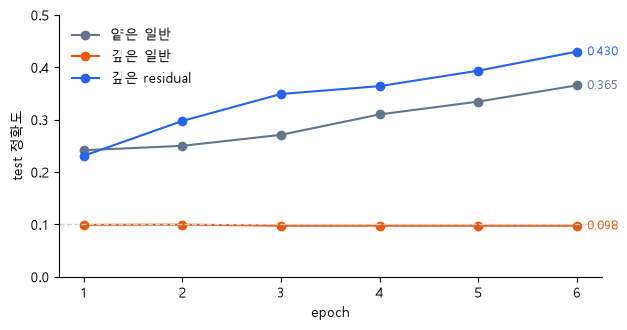

In [23]:
# 학습 곡선: epoch마다 test 정확도 (세 모델 같은 축)
import matplotlib.pyplot as plt  # 그래프

plt.rcParams["font.family"] = "Malgun Gothic"  # 한글 글꼴 (Windows)
fig, ax = plt.subplots(figsize=(7, 3.4))
styles = {"얕은 일반": "#64748b", "깊은 일반": "#ea580c", "깊은 residual": "#2563eb"}
for name, (model, history) in results.items():
    test_acc = [te for _, _, te in history]  # (loss, train acc, test acc)
    epochs = range(1, len(test_acc) + 1)
    ax.plot(epochs, test_acc, marker="o", color=styles[name], label=name)
    ax.text(len(test_acc) + 0.1, test_acc[-1], f"{test_acc[-1]:.3f}",
            va="center", fontsize=9, color=styles[name])
ax.axhline(0.1, color="#cbd5e1", ls="--", lw=1)  # 10개 중 찍기 = 0.1
ax.set_xlabel("epoch")
ax.set_ylabel("test 정확도")
ax.set_ylim(0, 0.5)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [24]:
# 마지막 epoch 비교: 손실 · 정확도 · 간격(train - test)
print("모델          | train loss | train acc | test acc | 간격")
for name, (model, history) in results.items():
    loss_, tr, te = history[-1]
    print(f"{name:<12} | {loss_:.4f}     | {tr:.3f}     | {te:.3f}    | "
          f"{tr - te:+.3f}")


# 틀린 것들은 아무렇게나 틀렸나: 깊은 residual의 혼동 짝 상위 3개
model = results["깊은 residual"][0]
model.eval()
pairs = torch.zeros(10, 10, dtype=torch.int64)  # [정답, 예측] 횟수
with torch.no_grad():
    for images, labels in test_loader:
        pred = model(images.to(device)).argmax(dim=1).cpu()
        for t, p in zip(labels.tolist(), pred.tolist()):
            pairs[t, p] += 1
wrong = pairs.clone()
wrong.fill_diagonal_(0)  # 맞힌 칸 지우기
print("틀린 수:", int(wrong.sum()), "/", len(test_set))
names = train_full.classes
for idx in wrong.flatten().argsort(descending=True)[:3].tolist():
    t, p = divmod(idx, 10)
    print(f"  {names[t]} → {names[p]} {int(wrong[t, p])}번")

모델          | train loss | train acc | test acc | 간격
얕은 일반        | 1.7046     | 0.364     | 0.365    | -0.002
깊은 일반        | 2.3025     | 0.100     | 0.098    | +0.003
깊은 residual  | 1.5770     | 0.415     | 0.430    | -0.015


틀린 수: 1140 / 2000
  ship → airplane 78번
  cat → dog 60번
  automobile → truck 60번


**결과** · 예측 정답은 깊은 일반은 오히려 **학습조차 안 됨** (6 epoch 내내 loss 2.30 · 정확도 0.10 = 찍기) — 같은 깊이의 residual은 0.430으로 얕은 일반(0.365)보다도 높음

- `얕은 일반 | 합성곱 9층 | 파라미터 121,226` — stage마다 블록 1개 · 기준 모델
- `깊은 일반 | 합성곱 21층 | 파라미터 315,210` — stage마다 블록 3개 · 1 + 2 + 3 × 3 × 2 = 21층
- `깊은 residual | 합성곱 21층 | 파라미터 315,210` — 깊은 일반과 층 수 · 파라미터까지 같음 → 다른 것은 `+ x` 한 줄
- `첫 loss 2.3088` — 깊은 일반도 출발은 ln(10) ≈ 2.30 근처 → 출력 · 손실 연결 오류가 아님
- `epoch 6 | train loss 2.3025 | train acc 0.100 | test acc 0.098` — 깊은 일반: 6 epoch 내내 찍기 수준 (train부터 나쁨 = degradation)
- `epoch 6 | train loss 1.7046 | train acc 0.364 | test acc 0.365` — 얕은 일반: 천천히 학습됨
- `epoch 6 | train loss 1.5770 | train acc 0.415 | test acc 0.430` — 깊은 residual: 같은 깊이인데 학습되고 얕은 일반보다 test 6.5%p 높음
- `깊은 residual | 1.5770 | 0.415 | 0.430 | -0.015` — 간격이 음수 → 아직 과적합 아님 (train acc는 epoch 동안의 평균이라 끝난 뒤 잰 test보다 낮게 나올 수 있음)
- `틀린 수: 1140 / 2000` — 깊은 residual도 아직 57%를 틀림 → 6 epoch · 1만 장 · BatchNorm 없는 짧은 실험
- `ship → airplane 78번` · `cat → dog 60번` — 겉모습이 비슷한 짝에 몰림 (슬라이드 DAY02 81쪽의 1위 혼동 짝과 같은 종류)

**세 곡선에 이름 붙이기** (DAY02 189쪽 규칙)

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">모델</th>
<th style="text-align: left;">train · test 모양</th>
<th style="text-align: left;">이름</th>
<th style="text-align: left;">다음에 할 일</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">얕은 일반</td>
<td style="text-align: left;">둘 다 천천히 오르고 붙어 있음</td>
<td style="text-align: left;">아직 배우는 중</td>
<td style="text-align: left;">epoch 늘리기</td>
</tr>
<tr>
<td style="text-align: left;">깊은 일반</td>
<td style="text-align: left;">둘 다 0.10에서 안 움직임 · 얕은 모델보다 train부터 나쁨</td>
<td style="text-align: left;">degradation (과적합 아님)</td>
<td style="text-align: left;">구조를 바꿈 → shortcut · BatchNorm</td>
</tr>
<tr>
<td style="text-align: left;">깊은 residual</td>
<td style="text-align: left;">둘 다 오르고 붙어 있음 · 얕은 모델보다 빠름</td>
<td style="text-align: left;">아직 배우는 중 (가장 빠름)</td>
<td style="text-align: left;">epoch · 데이터 늘리기, 간격이 벌어지면 Dropout</td>
</tr>
</tbody>
</table>

> ⚠️ **주의** · 한 번의 실행 · 한 seed · 1만 장 · 6 epoch · BatchNorm 없는 조건의 결과 → "residual이 항상 6.5%p 높다"가 아니라 "이 조건에서 깊은 일반은 학습이 멈추고 residual은 학습됐다"까지만 말할 수 있음 · 원인을 "기울기 소실" 하나로 단정하지 않기 (DAY02 200 ~ 202쪽) · GPU에서 실행한 값

> ✅ **한 줄 정리** · 같은 21층 · 같은 파라미터에서 일반 CNN은 학습이 멈췄고 `+ x` 한 줄을 더한 residual CNN은 학습되어 얕은 모델보다 높았으므로, 깊게 쌓을 때는 shortcut이 학습을 가능하게 한다.

**딥러닝 코드에서는** · 실제 프로젝트는 처음부터 쌓지 않고 `torchvision.models.resnet18(weights="DEFAULT")`처럼 사전학습된 ResNet을 불러와 `model.fc`만 바꿔 학습 (이미지분류 정리본) — 이 권에서 본 stage · projection · GAP 머리 · `train()` / `eval()`이 그 코드 안에 그대로 있음

### 7장 더 알아보기 · epoch별 값과 방법별 차이

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">epoch</th>
<th style="text-align: left;">얕은 일반 (9층)</th>
<th style="text-align: left;">깊은 일반 (21층)</th>
<th style="text-align: left;">깊은 residual (21층)</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">0.241</td>
<td style="text-align: left;">0.099</td>
<td style="text-align: left;">0.231</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">0.250</td>
<td style="text-align: left;">0.100</td>
<td style="text-align: left;">0.297</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">0.271</td>
<td style="text-align: left;">0.098</td>
<td style="text-align: left;">0.349</td>
</tr>
<tr>
<td style="text-align: left;">4</td>
<td style="text-align: left;">0.310</td>
<td style="text-align: left;">0.098</td>
<td style="text-align: left;">0.364</td>
</tr>
<tr>
<td style="text-align: left;">5</td>
<td style="text-align: left;">0.335</td>
<td style="text-align: left;">0.098</td>
<td style="text-align: left;">0.394</td>
</tr>
<tr>
<td style="text-align: left;">6</td>
<td style="text-align: left;">0.365</td>
<td style="text-align: left;">0.098</td>
<td style="text-align: left;"><strong>0.430</strong></td>
</tr>
<tr>
<td style="text-align: left;">마지막 train loss</td>
<td style="text-align: left;">1.7046</td>
<td style="text-align: left;">2.3025 (멈춤)</td>
<td style="text-align: left;">1.5770</td>
</tr>
</tbody>
</table>

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">방법</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">언제 쓰나</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">깊은 일반 CNN (BatchNorm 없음)</td>
<td style="text-align: left;">층마다 처음부터 만듦 · 깊어지면 학습 시작조차 어려움</td>
<td style="text-align: left;">깊이 10층 안팎의 작은 모델</td>
</tr>
<tr>
<td style="text-align: left;">깊은 residual CNN</td>
<td style="text-align: left;"><code>+ x</code>로 입력이 지나가는 길 · 같은 파라미터로 학습됨</td>
<td style="text-align: left;">깊게 쌓을 때 (ResNet 계열)</td>
</tr>
<tr>
<td style="text-align: left;">BatchNorm 추가 (이 실습에서는 뺌)</td>
<td style="text-align: left;">층마다 값의 크기를 맞춰 학습을 안정시킴</td>
<td style="text-align: left;">실제 구현은 residual + BatchNorm을 함께 (3-2)</td>
</tr>
<tr>
<td style="text-align: left;">정확도 하나만 보기</td>
<td style="text-align: left;">모델 순위만 앎</td>
<td style="text-align: left;">빠른 비교</td>
</tr>
<tr>
<td style="text-align: left;">곡선 · 간격 · 혼동 짝까지 보기</td>
<td style="text-align: left;">underfitting · 과적합 · degradation 구분 · 틀리는 결</td>
<td style="text-align: left;">다음 실험을 고를 때 (기본)</td>
</tr>
</tbody>
</table>

---
## 그래서 오늘 무엇을 배웠는가?

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">학습 목표</th>
<th style="text-align: left;">할 수 있게 된 것</th>
<th style="text-align: left;">확인 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1. 풀링 · GAP</td>
<td style="text-align: left;">4×4 → max <code>[[8, 5], [6, 7]]</code> · avg를 손으로 구하고, 이동 불변은 창 안에서만임을 확인</td>
<td style="text-align: left;">1-1 · 1-2 · 1-3</td>
</tr>
<tr>
<td style="text-align: left;">2. shape · 파라미터</td>
<td style="text-align: left;">몸통을 층마다 손으로 적어 코드와 일치 · Flatten 모델 106,538 vs GAP 모델 66,218</td>
<td style="text-align: left;">2-1 · 2-2</td>
</tr>
<tr>
<td style="text-align: left;">3. 모양 에러</td>
<td style="text-align: left;"><code>1x16384 and 4096x10</code>에서 원인이 64×64 입력임을 찾고 GAP 머리로 해결</td>
<td style="text-align: left;">2-3</td>
</tr>
<tr>
<td style="text-align: left;">4. 두 스위치</td>
<td style="text-align: left;">train/eval × no_grad 4가지 조합에서 출력 고정 여부 · 기울기 기록을 구분</td>
<td style="text-align: left;">3-1 · 3-2 · 3-3</td>
</tr>
<tr>
<td style="text-align: left;">5. VGG · ResNet</td>
<td style="text-align: left;">3×3 세 번 = 7×7 범위 · 가중치 55%, <code>+ x</code>로 21층이 학습됨 (0.098 → 0.430)</td>
<td style="text-align: left;">5-1 · 6-1 · 7</td>
</tr>
</tbody>
</table>

### 주제별 한 줄 · 반드시 기억할 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">등급</th>
<th style="text-align: left;">주제</th>
<th style="text-align: left;">반드시 기억할 것</th>
<th style="text-align: left;">딥러닝 코드에서</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">max · avg 풀링</td>
<td style="text-align: left;">창마다 하나 · 파라미터 0 · 서로 다른 것을 버림</td>
<td style="text-align: left;"><code>nn.MaxPool2d(2)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">풀링의 보장</td>
<td style="text-align: left;">면적 1/4 · 계산 감소만 확실, 이동 불변은 아님</td>
<td style="text-align: left;">입력은 2로 나누어떨어지게</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">GAP</td>
<td style="text-align: left;">채널마다 평균 → <code>(N, C)</code> · 위치 버림</td>
<td style="text-align: left;"><code>nn.AdaptiveAvgPool2d(1)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">머리 두 가지</td>
<td style="text-align: left;">Flatten은 많고 크기 고정, GAP은 적고 크기 무관</td>
<td style="text-align: left;">요즘 기본은 GAP 머리</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">풀링 vs stride 2</td>
<td style="text-align: left;">고정 · 0개 vs 학습되는 줄이기</td>
<td style="text-align: left;">VGG는 pool, ResNet은 stride 2</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">shape 추적</td>
<td style="text-align: left;">채널은 Conv, 면적은 Pool, N은 그대로</td>
<td style="text-align: left;"><code>print(x.shape)</code> · summary</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">파라미터 수</td>
<td style="text-align: left;">Conv는 면적 없음, Flatten 뒤 Linear가 폭증</td>
<td style="text-align: left;">모델 크기는 머리부터 확인</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">모양 에러</td>
<td style="text-align: left;"><code>(AxB and CxD)</code>의 B ≠ C · 원인은 앞쪽</td>
<td style="text-align: left;">더미 입력 · GAP 머리</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">Dropout</td>
<td style="text-align: left;">학습 때만 끄고 1/(1-p)배 · 평가 때 그대로</td>
<td style="text-align: left;">분류기 앞 <code>nn.Dropout(0.5)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">BatchNorm</td>
<td style="text-align: left;">학습은 배치 통계, 평가는 running 통계</td>
<td style="text-align: left;"><code>Conv → BN → ReLU</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">두 스위치</td>
<td style="text-align: left;"><code>eval()</code> = 층 동작, <code>no_grad()</code> = 기울기 기록</td>
<td style="text-align: left;">평가 = 둘 다</td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">LeNet</td>
<td style="text-align: left;">찾기 · 줄이기 · 판정의 원조 · 서브샘플링 ≠ MaxPool</td>
<td style="text-align: left;">골격의 순서</td>
</tr>
<tr>
<td style="text-align: center;"><code>B</code></td>
<td style="text-align: left;">AlexNet</td>
<td style="text-align: left;">규모 확장 · ReLU · Dropout · GPU · 파라미터 96% Linear</td>
<td style="text-align: left;"><code>models.alexnet()</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">3×3 반복</td>
<td style="text-align: left;">범위 2n + 1 · 같은 범위에서 가중치 적음</td>
<td style="text-align: left;">거의 모든 CNN</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">VGG 문법</td>
<td style="text-align: left;">3×3 · padding 1 · 블록 끝 pool · 채널 2배</td>
<td style="text-align: left;">직접 설계할 때의 기본</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">1×1</td>
<td style="text-align: left;">자리 유지 · 채널만 바꿈</td>
<td style="text-align: left;">projection · bottleneck</td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">residual</td>
<td style="text-align: left;">출력 = 입력 + 고칠 부분 · degradation 대응</td>
<td style="text-align: left;"><code>torch.relu(out + x)</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">projection</td>
<td style="text-align: left;">shape가 바뀌면 1×1 · stride 2로 shortcut 맞춤</td>
<td style="text-align: left;"><code>downsample</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">stage</td>
<td style="text-align: left;">첫 블록만 shape 변화 · 마지막 GAP</td>
<td style="text-align: left;"><code>resnet18().layer1 ~ 4</code></td>
</tr>
<tr>
<td style="text-align: center;"><code>A</code></td>
<td style="text-align: left;">종합</td>
<td style="text-align: left;">같은 21층 · 같은 파라미터에서 일반은 학습이 멈추고 residual은 학습됨</td>
<td style="text-align: left;">깊은 모델은 shortcut</td>
</tr>
</tbody>
</table>

---
## 기억 확인 문제

위 내용을 **보지 않고** 답한 뒤, ✅ 한 줄 정리와 비교해 ○ (정확) · △ (일부) · × (모름)를 표시. △ · ×인 섹션만 다시 보기. 섹션 칸에 `점검`이 붙은 5개는 슬라이드 마지막 쪽(DAY02 249쪽) "스스로 점검하기"와 같은 질문.

### 1. 질문에 답하기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">🎯 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1 <code>점검</code></td>
<td style="text-align: left;">max pooling과 average pooling은 각각 무엇을 남기고 버리는가?</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">풀링이 확실히 보장하는 것과 보장하지 않는 것은?</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">GAP은 무엇을 남기고 버리며, 결과 shape는?</td>
</tr>
<tr>
<td style="text-align: left;">1-4</td>
<td style="text-align: left;">Flatten + Linear 머리와 GAP + Linear 머리의 차이는?</td>
</tr>
<tr>
<td style="text-align: left;">1-5</td>
<td style="text-align: left;">풀링과 stride 2 합성곱은 무엇이 다른가?</td>
</tr>
<tr>
<td style="text-align: left;">2-1 <code>점검</code></td>
<td style="text-align: left;">코드에서 채널을 바꾸는 줄과 면적을 바꾸는 줄은 각각 무엇인가?</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">Conv와 Linear의 파라미터 공식에서 결정적인 차이는?</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;"><code>mat1 and mat2 shapes cannot be multiplied (1x16384 and 4096x10)</code>을 읽으면?</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">Dropout은 학습 · 평가 때 어떻게 다르고, 왜 1/(1-p)배 하는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">BatchNorm은 학습 · 평가 때 어떤 통계를 쓰는가?</td>
</tr>
<tr>
<td style="text-align: left;">3-3</td>
<td style="text-align: left;"><code>model.eval()</code>과 <code>torch.no_grad()</code>의 차이와 평가할 때 필요한 것은?</td>
</tr>
<tr>
<td style="text-align: left;">4-1 <code>점검</code></td>
<td style="text-align: left;">LeNet이 세운 순서와, 그 서브샘플링이 MaxPool과 다른 점은?</td>
</tr>
<tr>
<td style="text-align: left;">4-2 <code>점검</code></td>
<td style="text-align: left;">AlexNet은 무엇이 새로 필요했고, 파라미터는 어디에 몰려 있나?</td>
</tr>
<tr>
<td style="text-align: left;">5-1</td>
<td style="text-align: left;">3×3 두 번과 5×5 한 번의 범위 · 가중치는?</td>
</tr>
<tr>
<td style="text-align: left;">5-2</td>
<td style="text-align: left;">VGG의 규칙 네 줄과 "VGG가 AlexNet보다 적다"의 참 · 거짓은?</td>
</tr>
<tr>
<td style="text-align: left;">5-3</td>
<td style="text-align: left;">1×1 합성곱이 하는 일은?</td>
</tr>
<tr>
<td style="text-align: left;">6-1 <code>점검</code></td>
<td style="text-align: left;">degradation은 과적합과 어떻게 다르고, residual 블록은 무엇을 바꾸나?</td>
</tr>
<tr>
<td style="text-align: left;">6-2</td>
<td style="text-align: left;">shape가 바뀌는 블록에서 shortcut은 어떻게 맞추나?</td>
</tr>
<tr>
<td style="text-align: left;">6-3</td>
<td style="text-align: left;">stage 안에서 shape가 바뀌는 곳은 어디인가?</td>
</tr>
<tr>
<td style="text-align: left;">7</td>
<td style="text-align: left;">같은 조건에서 깊은 일반 CNN과 residual CNN은 어떻게 달랐나?</td>
</tr>
</tbody>
</table>

#### 내 답 · 이 셀을 더블클릭해서 작성

**1-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-4** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**1-5** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**2-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**3-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**4-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**5-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-1** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-2** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**6-3** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

**7** · (여기에 답 작성) · ○ △ × 중 하나만 남기기

### 2. 코드로 답하기

아래 빈 셀에 직접 작성 후 실행.

1. `(8, 64, 15, 15)`에 `MaxPool2d(2)`를 기본 설정과 `ceil_mode=True`로 적용한 shape
2. 몸통 출력 `(2, 128, 4, 4)` 뒤에 붙일 Flatten 머리 · GAP 머리(10종)의 파라미터 수
3. Dropout(p=0.25)를 학습 모드로 만든 뒤 `torch.ones(8)`에 적용했을 때 살아남은 값, 평가 모드 출력의 합
4. 채널 64 → 64에서 3×3 세 번과 7×7 한 번의 가중치 수 (bias 제외)
5. `(1, 32, 16, 16)` 입력을 `(1, 64, 8, 8)`로 바꾸는 projection shortcut의 파라미터 수와 출력 shape

In [25]:
# 코드 문제 직접 작성

### 3. 변형 문제 · 조건을 바꿔 다시 풀기

1. 2-1의 몸통(`features`)에 **48×48** 입력을 넣으면 층마다 H · W와 Flatten 길이는? 손으로 적은 뒤 코드로 확인
2. 몸통 출력이 `(N, 256, 4, 4)`일 때 10종 분류용 Flatten 머리와 GAP 머리의 파라미터 수는?
3. `nn.Dropout(p=0.2)`를 학습 모드로 `torch.ones(10)`에 적용하면 살아남은 값은 얼마가 되고, 평가 모드 출력의 합은?

In [26]:
# 변형 문제 직접 작성

### 4. 모범 답안 · 1 ~ 3을 다 푼 뒤에 보기

#### 질문 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">섹션</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1-1</td>
<td style="text-align: left;">max는 가장 센 반응을 남기고 퍼진 정도를 버림, average는 전체 세기를 남기고 뾰족한 반응을 버림</td>
</tr>
<tr>
<td style="text-align: left;">1-2</td>
<td style="text-align: left;">보장: 면적 축소(2×2면 원소 1/4) · 파라미터 0. 보장 안 함: 이동 불변 · 일반화 · 과적합 감소</td>
</tr>
<tr>
<td style="text-align: left;">1-3</td>
<td style="text-align: left;">채널마다 피처맵 평균 하나 → <code>(N, C)</code> (면적 무관), 위치는 모두 버림</td>
</tr>
<tr>
<td style="text-align: left;">1-4</td>
<td style="text-align: left;">Flatten은 자리마다 가중치(많음 · 입력 크기 고정), GAP은 채널 평균만(적음 · 크기 무관)</td>
</tr>
<tr>
<td style="text-align: left;">1-5</td>
<td style="text-align: left;">풀링은 파라미터 0 · 채널마다 고정 규칙, stride 2 합성곱은 채널을 섞으며 줄이는 법까지 학습</td>
</tr>
<tr>
<td style="text-align: left;">2-1</td>
<td style="text-align: left;">채널은 Conv(<code>padding=1</code>이면 면적 그대로), 면적은 MaxPool · GAP. ReLU는 아무것도 안 바꿈</td>
</tr>
<tr>
<td style="text-align: left;">2-2</td>
<td style="text-align: left;">Conv는 out × (in × k × k) + out으로 면적이 없고, Linear는 입력 길이가 그대로 곱해짐</td>
</tr>
<tr>
<td style="text-align: left;">2-3</td>
<td style="text-align: left;">흘러온 길이 16384가 Linear가 기다린 4096과 다름 → 원인은 입력 크기(64×64) · 앞 층</td>
</tr>
<tr>
<td style="text-align: left;">3-1</td>
<td style="text-align: left;">학습 때만 일부를 0으로 · 남은 값 1/(1-p)배로 총량 유지, 평가 때는 그대로</td>
</tr>
<tr>
<td style="text-align: left;">3-2</td>
<td style="text-align: left;">학습 때는 지금 배치 통계(+ running 갱신), 평가 때는 저장된 running 통계</td>
</tr>
<tr>
<td style="text-align: left;">3-3</td>
<td style="text-align: left;"><code>eval()</code>은 층 동작, <code>no_grad()</code>는 기울기 기록. 평가할 때는 둘 다</td>
</tr>
<tr>
<td style="text-align: left;">4-1</td>
<td style="text-align: left;">찾기 · 줄이기를 번갈아 하고 마지막에 판정. 서브샘플링은 학습되는 계수 · 편향이 있음</td>
</tr>
<tr>
<td style="text-align: left;">4-2</td>
<td style="text-align: left;">대규모 데이터 · GPU · ReLU · Dropout. 파라미터의 약 96%가 Linear</td>
</tr>
<tr>
<td style="text-align: left;">5-1</td>
<td style="text-align: left;">둘 다 범위 5, 가중치 18C² vs 25C² (3×3 두 번이 약 28% 적음)</td>
</tr>
<tr>
<td style="text-align: left;">5-2</td>
<td style="text-align: left;">3×3 고정 · padding 1 · 블록 끝 pool · 공간 절반이면 채널 2배. 거짓 (VGG16이 약 2.3배)</td>
</tr>
<tr>
<td style="text-align: left;">5-3</td>
<td style="text-align: left;">자리는 그대로 두고 채널만 다시 씀 (자리마다 같은 Linear)</td>
</tr>
<tr>
<td style="text-align: left;">6-1</td>
<td style="text-align: left;">과적합은 train 좋고 test 나쁨, degradation은 train부터 나쁨. 출력 = 입력 + 고칠 부분</td>
</tr>
<tr>
<td style="text-align: left;">6-2</td>
<td style="text-align: left;">shortcut에 1×1 · stride 2 합성곱(projection)으로 채널 · 크기를 맞춤</td>
</tr>
<tr>
<td style="text-align: left;">6-3</td>
<td style="text-align: left;">첫 블록 (stride 2 · 채널 2배 · projection), 나머지는 그대로 더함</td>
</tr>
<tr>
<td style="text-align: left;">7</td>
<td style="text-align: left;">같은 조건에서 얕은 일반 0.365 · 깊은 일반 0.098 (train loss 2.30에 멈춤 = 학습 실패) · 깊은 residual 0.430. <code>+ x</code> 한 줄 차이로 깊은 일반만 학습되지 않음</td>
</tr>
</tbody>
</table>

#### 코드 문제 답

```python
# 1. 기본은 내림 15 → 7 · ceil_mode는 올림 15 → 8
x = torch.zeros(8, 64, 15, 15)
floor = nn.MaxPool2d(2)(x).shape[-1]
ceil = nn.MaxPool2d(2, ceil_mode=True)(x).shape[-1]
print(floor, ceil)  # 7 8

# 2. Flatten 128 × 4 × 4 × 10 + 10 · GAP 128 × 10 + 10
flat = sum(p.numel() for p in nn.Linear(128 * 4 * 4, 10).parameters())
gap = sum(p.numel() for p in nn.Linear(128, 10).parameters())
print(flat, gap)  # 20490 1290

# 3. 살아남은 값 1 ÷ (1 - 0.25) · 평가 모드는 그대로
drop = nn.Dropout(p=0.25)
print(round(drop(torch.ones(8)).max().item(), 4))  # 1.3333
drop.eval()
print(drop(torch.ones(8)).sum().item())  # 8.0

# 4. 27C² vs 49C²
w3 = 3 * nn.Conv2d(64, 64, 3, bias=False).weight.numel()
w7 = nn.Conv2d(64, 64, 7, bias=False).weight.numel()
print(w3, w7)  # 110592 200704

# 5. 1×1 · stride 2: 64 × 32 + 64 · 16 → 8
proj = nn.Conv2d(32, 64, kernel_size=1, stride=2)
out = proj(torch.zeros(1, 32, 16, 16))
n = sum(p.numel() for p in proj.parameters())
print(n, tuple(out.shape))  # 2112 (1, 64, 8, 8)
```

#### 변형 문제 답

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">문제</th>
<th style="text-align: left;">답</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1</td>
<td style="text-align: left;">48 → 48 → 24 → 24 → 12 (Conv는 그대로 · Pool만 절반) · Flatten 64 × 12 × 12 = 9216 → <code>Linear(4096, 10)</code>과 안 맞아 에러</td>
</tr>
<tr>
<td style="text-align: left;">2</td>
<td style="text-align: left;">Flatten 4096 × 10 + 10 = 40970 · GAP 256 × 10 + 10 = 2570</td>
</tr>
<tr>
<td style="text-align: left;">3</td>
<td style="text-align: left;">1 ÷ (1 - 0.2) = 1.25배 → 살아남은 값 1.25 · 평가 모드 출력 합 10.0</td>
</tr>
</tbody>
</table>

---
## 오답 노트

틀린 문제는 정답을 베끼지 말고 **원인**을 적음. 다음 복습 때 이 표의 "재발 방지 질문"부터 스스로에게 물어보기.

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">틀린 내용</th>
<th style="text-align: left;">틀린 이유</th>
<th style="text-align: left;">올바른 원칙</th>
<th style="text-align: left;">재발 방지 질문</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">(예) 평가 점수가 매번 다르게 나옴</td>
<td style="text-align: left;"><code>model.eval()</code>을 안 불러 Dropout이 켜져 있었음</td>
<td style="text-align: left;">평가 = <code>eval()</code> + <code>no_grad()</code></td>
<td style="text-align: left;">평가 루프 첫 줄에 <code>eval()</code>이 있나?</td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
<tr>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
<td style="text-align: left;"></td>
</tr>
</tbody>
</table>

---
## 면접 30초 답변

**Q1. 풀링은 왜 쓰고, 무엇을 보장하나요?**
> 풀링은 겹치지 않는 창마다 값 하나만 남겨 면적을 줄이는 고정 연산이라, 2×2면 원소 수가 1/4이 되어 다음 층의 계산량이 줄고 파라미터는 0개입니다. 확실히 보장하는 것은 이 크기와 계산량의 변화까지이고, 창 크기 안의 작은 이동만 뭉갤 뿐 이동 불변성이나 일반화 향상을 보장하지는 않습니다. max는 가장 센 반응을, average는 평균 세기를 남겨 서로 다른 정보를 버립니다.

**Q2. Global Average Pooling을 분류기 앞에 쓰는 이유는?**
> GAP은 채널마다 피처맵 전체를 평균 내어 숫자 하나로 만들기 때문에 입력 면적과 무관하게 채널 수만큼의 벡터가 나옵니다. 그래서 뒤의 Linear 입력 크기가 고정되어 입력 이미지 크기가 달라져도 모델이 동작하고, Flatten 뒤 Linear보다 파라미터가 훨씬 적습니다. 대신 어디서 반응했는지는 모두 버리므로 위치가 중요한 작업에는 맞지 않습니다.

**Q3. model.train()과 model.eval()은 무엇이 다른가요?**
> Dropout과 BatchNorm처럼 학습과 평가에서 다르게 동작하는 층의 모드를 바꿉니다. 학습 모드에서 Dropout은 매번 일부를 끄고 남은 값을 키우며, BatchNorm은 현재 배치의 통계로 정규화하고 running 통계를 갱신합니다. 평가 모드에서는 Dropout은 그대로 통과시키고 BatchNorm은 저장된 통계를 써서 결과가 항상 같습니다. 기울기 기록은 별개라서 평가할 때는 torch.no_grad()도 함께 씁니다.

**Q4. VGG가 3×3 커널만 반복해서 쓰는 이유는?**
> 3×3을 쌓으면 한 층마다 보는 범위가 2칸씩 넓어져 두 번이면 5×5, 세 번이면 7×7과 같은 범위를 봅니다. 같은 범위를 큰 커널 한 번으로 만들 때보다 가중치가 적고, 층 사이에 ReLU가 더 들어가 비선형성도 늘어납니다. 다만 이것은 같은 범위와 채널에서의 비교이고, VGG16 전체는 층과 채널이 많아 AlexNet보다 파라미터가 많습니다.

**Q5. ResNet의 shortcut은 어떤 문제를 해결하나요?**
> 층을 깊게 쌓았는데 학습 손실조차 얕은 모델보다 나빠지는 degradation 문제를 다룹니다. 출력을 입력과 층이 만든 값의 합으로 바꿔서, 층은 고칠 부분만 만들면 되고 고칠 게 없으면 0에 가깝게 두어 입력을 그대로 보낼 수 있습니다. 채널이나 크기가 바뀌는 블록에서는 1×1, stride 2 합성곱으로 shortcut의 shape를 맞춥니다. 미분이 항상 1 이상이 된다는 설명은 정확하지 않고, 기울기가 흐르는 길이 하나 더 생긴다는 것까지가 맞습니다.

---
## 최종 요약표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">함수·문법</th>
<th style="text-align: left;">소속</th>
<th style="text-align: left;">역할</th>
<th style="text-align: left;">코드에서 사용한 위치</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>nn.MaxPool2d(k)</code> · <code>nn.AvgPool2d(k)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">창마다 최댓값 · 평균 (파라미터 0)</td>
<td style="text-align: left;">1-1 <code>max_pool = nn.MaxPool2d(kernel_size=2)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>ceil_mode=True</code></td>
<td style="text-align: left;">MaxPool2d 인자</td>
<td style="text-align: left;">나누어떨어지지 않을 때 반쪽 창</td>
<td style="text-align: left;">1-2 <code>ceil = nn.MaxPool2d(2, ceil_mode=True)(torch.zeros…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.AdaptiveAvgPool2d(1)</code> · <code>x.mean(dim=(2, 3))</code></td>
<td style="text-align: left;">torch.nn · 텐서 메서드</td>
<td style="text-align: left;">GAP · 채널마다 평균 하나</td>
<td style="text-align: left;">1-3 <code>gap = nn.AdaptiveAvgPool2d(1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Flatten()</code> + <code>nn.Linear</code> vs GAP + <code>nn.Linear</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">분류기 머리 두 가지</td>
<td style="text-align: left;">1-4 <code>flat_head = nn.Sequential(nn.Flatten(), nn.Linear(…</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Conv2d(..., stride=2)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">학습되는 크기 줄이기</td>
<td style="text-align: left;">1-5 <code>sconv = nn.Conv2d(16, 16, 3, stride=2, padding=1)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Sequential(...)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">층을 순서대로 이어 붙인 몸통 · 모델</td>
<td style="text-align: left;">2-1 <code>features = nn.Sequential(</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>x.shape</code> · <code>tuple(x.shape)</code></td>
<td style="text-align: left;">텐서 속성</td>
<td style="text-align: left;">층마다 shape 확인</td>
<td style="text-align: left;">2-1 <code>before = tuple(x.shape)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>sum(p.numel() for p in m.parameters())</code></td>
<td style="text-align: left;">nn.Module · 텐서 메서드</td>
<td style="text-align: left;">파라미터 수</td>
<td style="text-align: left;">2-2 <code>real = [sum(p.numel() for p in m.parameters())</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>try:</code> · <code>except RuntimeError as e:</code></td>
<td style="text-align: left;">Python 예외 처리</td>
<td style="text-align: left;">일부러 낸 에러를 잡아 메시지 출력</td>
<td style="text-align: left;">2-3 <code>flat_model(torch.zeros(1, 3, 64, 64))</code> → <code>except RuntimeError as e:</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>with torch.no_grad():</code> + 더미 입력</td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">Flatten 길이 재기</td>
<td style="text-align: left;">2-3 <code>with torch.no_grad():</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Dropout(p)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">학습 때 일부를 0으로 · 남은 값 1/(1-p)배</td>
<td style="text-align: left;">3-1 <code>drop = nn.Dropout(p=0.5)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.BatchNorm2d(C)</code> · <code>running_mean</code></td>
<td style="text-align: left;">torch.nn · 속성</td>
<td style="text-align: left;">채널마다 정규화 · 저장된 통계</td>
<td style="text-align: left;">3-2 <code>bn = nn.BatchNorm2d(3)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>model.train()</code> · <code>model.eval()</code> · <code>model.training</code></td>
<td style="text-align: left;">nn.Module 메서드 · 속성</td>
<td style="text-align: left;">층 동작 모드 전환 · 확인</td>
<td style="text-align: left;">3-3 <code>getattr(model, mode)()</code> · <code>model.eval()</code> · <code>model.training</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.no_grad()</code> · <code>torch.set_grad_enabled()</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">기울기 기록 끄기 · 켜고 끄기</td>
<td style="text-align: left;">3-3 <code>with torch.set_grad_enabled(not use_no_grad):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>.grad_fn</code></td>
<td style="text-align: left;">텐서 속성</td>
<td style="text-align: left;">기울기 기록 여부 확인</td>
<td style="text-align: left;">3-3 <code>f"{out1.grad_fn is not None}")</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.AvgPool2d(2)</code> · <code>nn.Tanh()</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">LeNet 서브샘플링 · 활성 함수에 가장 가까운 지금의 층</td>
<td style="text-align: left;">4-1 <code>nn.Conv2d(1, 6, 5), nn.Tanh(), nn.AvgPool2d(2),</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>models.alexnet(weights=None)</code></td>
<td style="text-align: left;">torchvision.models</td>
<td style="text-align: left;">AlexNet 구조만 (내려받지 않음)</td>
<td style="text-align: left;">4-2 <code>alex = models.alexnet(weights=None)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>model.modules()</code> · <code>isinstance(m, nn.Conv2d)</code></td>
<td style="text-align: left;">nn.Module · Python 내장</td>
<td style="text-align: left;">층 종류별로 세기</td>
<td style="text-align: left;">4-2 <code>n_conv = sum(p.numel() for m in alex.modules() if …</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>model.classifier</code></td>
<td style="text-align: left;">AlexNet 속성</td>
<td style="text-align: left;">분류기 부분 (Dropout 위치 확인)</td>
<td style="text-align: left;">4-2 <code>enumerate(alex.classifier)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>x.grad</code> (수용 영역 세기)</td>
<td style="text-align: left;">autograd</td>
<td style="text-align: left;">출력 하나가 영향을 받은 입력 칸</td>
<td style="text-align: left;">5-1 <code>return int((x.grad[0, 0, 10] != 0).sum())</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.init.constant_()</code></td>
<td style="text-align: left;">torch.nn.init</td>
<td style="text-align: left;">가중치를 한 값으로 채우기</td>
<td style="text-align: left;">5-1 <code>nn.init.constant_(layer.weight, 1.0)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>models.vgg16(weights=None)</code> · <code>vgg.features</code></td>
<td style="text-align: left;">torchvision.models</td>
<td style="text-align: left;">VGG16 구조 · 몸통</td>
<td style="text-align: left;">5-2 <code>vgg = models.vgg16(weights=None)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Conv2d(cin, cout, kernel_size=1)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">자리 유지 · 채널만 바꾸기</td>
<td style="text-align: left;">5-3 <code>nn.Conv2d(256, 64, kernel_size=1, bias=False)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>.permute(0, 2, 3, 1)</code></td>
<td style="text-align: left;">텐서 메서드</td>
<td style="text-align: left;">채널을 맨 뒤로 (Linear와 비교)</td>
<td style="text-align: left;">5-3 <code>by_lin = lin(x.permute(0, 2, 3, 1)).permute(0, 3, …</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>class Block(nn.Module)</code> · <code>forward</code></td>
<td style="text-align: left;">nn.Module 상속</td>
<td style="text-align: left;">블록 직접 만들기 (02 Python클래스 4장)</td>
<td style="text-align: left;">6-3 <code>class Block(nn.Module):</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>torch.relu(out + x)</code></td>
<td style="text-align: left;">torch</td>
<td style="text-align: left;">residual 더하기 (shortcut)</td>
<td style="text-align: left;">6-1 <code>return torch.relu(out + x)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Identity()</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">그대로 통과 (shape가 같을 때 shortcut)</td>
<td style="text-align: left;">6-3 <code>self.short = nn.Identity()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Conv2d(cin, cout, 1, stride=2)</code></td>
<td style="text-align: left;">torch.nn</td>
<td style="text-align: left;">projection shortcut</td>
<td style="text-align: left;">6-2 <code>proj = nn.Conv2d(64, 128, kernel_size=1, stride=2)</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>nn.Sequential(*layers)</code></td>
<td style="text-align: left;">torch.nn · Python 언패킹</td>
<td style="text-align: left;">블록 목록으로 stage 만들기</td>
<td style="text-align: left;">6-3 <code>return nn.Sequential(*layers)</code></td>
</tr>
</tbody>
</table>

### 할 것 · 하지 말 것

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">✅ 할 것</th>
<th style="text-align: left;">⚠️ 하지 말 것</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">풀링 효과는 "크기 · 계산"으로 말하기</td>
<td style="text-align: left;">"풀링 = 이동 불변 · 일반화"를 단정</td>
</tr>
<tr>
<td style="text-align: left;">분류기 머리는 GAP으로 (입력 크기가 바뀔 수 있으면)</td>
<td style="text-align: left;"><code>Linear(64 * 8 * 8, 10)</code>처럼 입력 크기를 숨겨 두기</td>
</tr>
<tr>
<td style="text-align: left;">층마다 shape를 적고 더미 입력으로 검증</td>
<td style="text-align: left;">에러 난 줄만 고치기 (원인은 앞쪽)</td>
</tr>
<tr>
<td style="text-align: left;">평가 전 <code>model.eval()</code> + <code>torch.no_grad()</code></td>
<td style="text-align: left;"><code>eval()</code>만 또는 <code>no_grad()</code>만</td>
</tr>
<tr>
<td style="text-align: left;">학습 루프 시작에 <code>model.train()</code></td>
<td style="text-align: left;">평가 뒤 <code>train()</code>으로 안 돌리기</td>
</tr>
<tr>
<td style="text-align: left;">같은 범위 비교에서만 "3×3이 싸다"고 말하기</td>
<td style="text-align: left;">조건을 떼고 "VGG가 더 가볍다"</td>
</tr>
<tr>
<td style="text-align: left;">shape가 바뀌는 블록에만 projection</td>
<td style="text-align: left;">shape가 같은데도 1×1 넣기</td>
</tr>
<tr>
<td style="text-align: left;">train · test 곡선을 둘 다 보고 이름 붙이기</td>
<td style="text-align: left;">train 정확도 하나로 좋은 모델이라 판단</td>
</tr>
</tbody>
</table>

### 헷갈리는 짝 한눈에 보기

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">짝</th>
<th style="text-align: left;">차이</th>
<th style="text-align: left;">결론</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">MaxPool vs AvgPool</td>
<td style="text-align: left;">가장 센 값 vs 평균</td>
<td style="text-align: left;">서로 다른 것을 버림 · 몸통은 보통 Max</td>
</tr>
<tr>
<td style="text-align: left;">MaxPool vs GAP</td>
<td style="text-align: left;">2×2마다 · 면적 1/4 vs 채널 전체 · 1×1</td>
<td style="text-align: left;">중간은 Max, 맨 끝은 GAP</td>
</tr>
<tr>
<td style="text-align: left;">풀링 vs stride 2 합성곱</td>
<td style="text-align: left;">파라미터 0 · 고정 vs 학습되는 줄이기</td>
<td style="text-align: left;">둘 다 면적 절반</td>
</tr>
<tr>
<td style="text-align: left;">Flatten + Linear vs GAP + Linear</td>
<td style="text-align: left;">자리마다 가중치 · 크기 고정 vs 채널 평균 · 크기 무관</td>
<td style="text-align: left;">요즘 기본은 GAP</td>
</tr>
<tr>
<td style="text-align: left;">이동 불변 vs 창 안 뭉갬</td>
<td style="text-align: left;">보장 vs 창 크기만큼만</td>
<td style="text-align: left;">풀링은 이동 불변을 보장하지 않음</td>
</tr>
<tr>
<td style="text-align: left;">에러 난 줄 vs 원인</td>
<td style="text-align: left;">Linear vs 입력 크기 · 앞 층</td>
<td style="text-align: left;">메시지의 두 숫자로 추적</td>
</tr>
<tr>
<td style="text-align: left;"><code>train()</code> vs <code>eval()</code></td>
<td style="text-align: left;">Dropout 켬 · BN 배치 통계 vs Dropout 끔 · BN 저장 통계</td>
<td style="text-align: left;">평가 전 <code>eval()</code></td>
</tr>
<tr>
<td style="text-align: left;"><code>eval()</code> vs <code>no_grad()</code></td>
<td style="text-align: left;">층 동작 vs 기울기 기록</td>
<td style="text-align: left;">평가할 때는 둘 다</td>
</tr>
<tr>
<td style="text-align: left;">Dropout train vs eval</td>
<td style="text-align: left;">끄고 1/(1-p)배 vs 그대로</td>
<td style="text-align: left;">평가가 매번 같아야 함</td>
</tr>
<tr>
<td style="text-align: left;">서브샘플링 vs MaxPool</td>
<td style="text-align: left;">학습 값 있음 vs 0개</td>
<td style="text-align: left;">이름이 비슷해도 다른 연산</td>
</tr>
<tr>
<td style="text-align: left;">3×3 두 번 vs 5×5 한 번</td>
<td style="text-align: left;">같은 범위 5 · 18C² vs 25C²</td>
<td style="text-align: left;">작은 커널 반복</td>
</tr>
<tr>
<td style="text-align: left;">1×1 vs 3×3</td>
<td style="text-align: left;">자리 유지 · 채널만 vs 이웃까지 섞음</td>
<td style="text-align: left;">채널 수 맞추기는 1×1</td>
</tr>
<tr>
<td style="text-align: left;">일반 블록 vs residual 블록</td>
<td style="text-align: left;">처음부터 만듦 vs 입력 + 고칠 부분</td>
<td style="text-align: left;">깊으면 residual</td>
</tr>
<tr>
<td style="text-align: left;">overfitting vs degradation</td>
<td style="text-align: left;">train 좋고 test 나쁨 vs train부터 나쁨</td>
<td style="text-align: left;">train · test 둘 다 봐야 구분</td>
</tr>
<tr>
<td style="text-align: left;">identity vs projection shortcut</td>
<td style="text-align: left;">그냥 더함 vs 1×1로 shape 맞춤</td>
<td style="text-align: left;">shape가 바뀌는 첫 블록만 projection</td>
</tr>
</tbody>
</table>

---
## 다음 복습일

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">언제</th>
<th style="text-align: left;">할 일</th>
<th style="text-align: left;">걸리는 시간</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">내일</td>
<td style="text-align: left;">기억 확인 문제 1을 자료 없이 다시 답하고 오답 노트 갱신</td>
<td style="text-align: left;">15분</td>
</tr>
<tr>
<td style="text-align: left;">3일 뒤</td>
<td style="text-align: left;">변형 문제 3개 · 2-1 shape 추적표와 2-2 계산표를 가리고 다시 채우기</td>
<td style="text-align: left;">25분</td>
</tr>
<tr>
<td style="text-align: left;">7일 뒤</td>
<td style="text-align: left;">6-3의 작은 ResNet을 직접 다시 짜서 stage마다 shape · 파라미터를 먼저 손으로 적고 실행</td>
<td style="text-align: left;">30분</td>
</tr>
<tr>
<td style="text-align: left;">14일 뒤</td>
<td style="text-align: left;">오답 노트에 남은 문제만 · CNN-1 · 2의 ✅ 한 줄 정리만 이어 읽기</td>
<td style="text-align: left;">15분</td>
</tr>
</tbody>
</table>

---
## 부록

### 이 노트북을 만든 방법

CNN DAY02 슬라이드(250쪽, 블록 9 ~ 16)를 **중복 없이 6개 대단원 · 19개 섹션**으로 재구성하고, **7장 종합 실습**(같은 조건에서 깊은 일반 CNN vs 깊은 residual CNN을 CIFAR-10 부분집합으로 학습)으로 연결. 실습 노트북이 없어서 슬라이드 속 코드 조각을 모아 실행되는 코드로 다시 만들고, 결과는 모두 실행으로 확인함. 데이터는 **torchvision CIFAR-10**(32×32 컬러 10종). CNN-1과 겹치는 합성곱 계산 · 출력 크기 공식은 **참조로 대체**(CNN-1 5 · 6장). 💡 쉬운 설명 일부는 코드잇 CNN PDF를 보조 자료로 사용.

### 읽는 법

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">표시</th>
<th style="text-align: left;">의미</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;"><code>A</code> · <code>B</code></td>
<td style="text-align: left;"><strong>A</strong> 딥러닝 코드에 바로 나오는 필수 · <strong>B</strong> 알아두면 되는 것</td>
</tr>
<tr>
<td style="text-align: left;">🎯</td>
<td style="text-align: left;">이번 섹션에서 답해야 할 질문</td>
</tr>
<tr>
<td style="text-align: left;">💡</td>
<td style="text-align: left;">쉬운 설명 · 비유</td>
</tr>
<tr>
<td style="text-align: left;">⚠️</td>
<td style="text-align: left;">자주 하는 실수</td>
</tr>
<tr>
<td style="text-align: left;">✅</td>
<td style="text-align: left;">기억할 결론 = 🎯 질문의 답</td>
</tr>
</tbody>
</table>

**섹션 구성** · 🎯 질문 → 💡 쉬운 설명 → 실행 흐름 → 먼저 예측 → 코드 → 예측 정답 · 결과 해설 → 차이 · 언제 쓰나 → ⚠️ 주의 → ✅ 한 줄 정리

**코드 주석** · 코드 위 = 이 단계에서 하는 일, 코드 옆 = 실행 흐름 · 문법 구조

### 원본 → 섹션 대응표

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">DAY02 쪽</th>
<th style="text-align: left;">원본 블록</th>
<th style="text-align: left;">슬라이드 코드 조각 (쪽)</th>
<th style="text-align: left;">섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">1 ~ 32</td>
<td style="text-align: left;">9 풀링과 Global Average Pooling</td>
<td style="text-align: left;">8 · 26</td>
<td style="text-align: left;">1-1 · 1-2 · 1-3 · 1-4 · 1-5 (1-5 stride 2 합성곱 비교는 DAY01 7장 + 보강)</td>
</tr>
<tr>
<td style="text-align: left;">33 ~ 62</td>
<td style="text-align: left;">10 CNN 모델 구현과 summary</td>
<td style="text-align: left;">37 · 38 · 39 · 47 · 48 · 52 · 54</td>
<td style="text-align: left;">2-1 · 2-2 · 2-3</td>
</tr>
<tr>
<td style="text-align: left;">63 ~ 89</td>
<td style="text-align: left;">11 학습시키고 읽어 보기 (곡선 · feature map · 오답)</td>
<td style="text-align: left;">—</td>
<td style="text-align: left;">7 (학습 곡선 · 간격 · 혼동 짝)</td>
</tr>
<tr>
<td style="text-align: left;">90 ~ 116</td>
<td style="text-align: left;">12 일부를 꺼 두고 배우기 (Dropout · 모드)</td>
<td style="text-align: left;">103 · 104 · 106 · 108 · 109</td>
<td style="text-align: left;">3-1 · 3-3 (3-2 BatchNorm은 168 · 240쪽 "오늘 다루지 않음"을 보강)</td>
</tr>
<tr>
<td style="text-align: left;">117 ~ 148</td>
<td style="text-align: left;">13 LeNet과 AlexNet</td>
<td style="text-align: left;">—</td>
<td style="text-align: left;">4-1 · 4-2</td>
</tr>
<tr>
<td style="text-align: left;">149 ~ 182</td>
<td style="text-align: left;">14 반복되는 3×3, 그리고 1×1</td>
<td style="text-align: left;">166 · 168</td>
<td style="text-align: left;">5-1 · 5-2 · 5-3</td>
</tr>
<tr>
<td style="text-align: left;">183 ~ 218</td>
<td style="text-align: left;">15 깊이의 문제 (degradation · residual)</td>
<td style="text-align: left;">209 · 210</td>
<td style="text-align: left;">6-1</td>
</tr>
<tr>
<td style="text-align: left;">219 ~ 250</td>
<td style="text-align: left;">16 블록에서 네트워크로 (projection · stage)</td>
<td style="text-align: left;">220 · 223 · 224 · 225 · 229 · 234 · 240</td>
<td style="text-align: left;">6-2 · 6-3</td>
</tr>
<tr>
<td style="text-align: left;">DAY01 117 ~ 120</td>
<td style="text-align: left;">4 train/eval과 no_grad는 다른 축</td>
<td style="text-align: left;">118</td>
<td style="text-align: left;">3-3 (CNN-1에서 넘겨받음)</td>
</tr>
<tr>
<td style="text-align: left;">코드잇 CNN PDF</td>
<td style="text-align: left;">보조 자료 (풀링 장단점 · GAP · 수용 영역)</td>
<td style="text-align: left;">—</td>
<td style="text-align: left;">💡 설명 · 1-3 · 5-1</td>
</tr>
</tbody>
</table>

### 전체 지도

#### 단원 연결 · 왜 이 순서로 배우는가

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">순서</th>
<th style="text-align: left;">배우는 이유</th>
<th style="text-align: left;">대단원</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;">합성곱만 쌓으면 숫자가 계속 커짐 → 면적을 줄이는 부품(풀링 · GAP)이 필요하다</td>
<td style="text-align: left;">풀링과 GAP</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;">부품을 이어 붙인 코드를 shape · 파라미터로 읽고, 깨질 때 에러를 읽는다</td>
<td style="text-align: left;">모델 구현 · shape 추적 · 모양 에러</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;">학습할 모델에는 학습 때만 다르게 도는 층(Dropout · BatchNorm)이 들어온다</td>
<td style="text-align: left;">train / eval 모드</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;">이 골격의 원조(LeNet)와 규모를 키운 모델(AlexNet)을 본다</td>
<td style="text-align: left;">LeNet → AlexNet</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;">커널 크기를 고민하는 대신 3×3을 반복하는 문법(VGG)과 1×1을 본다</td>
<td style="text-align: left;">VGG · 3×3 반복 · 1×1</td>
</tr>
<tr>
<td style="text-align: center;">6</td>
<td style="text-align: left;">깊게 쌓으면 학습이 나빠지는 문제를 shortcut으로 푼다</td>
<td style="text-align: left;">ResNet</td>
</tr>
<tr>
<td style="text-align: center;">7</td>
<td style="text-align: left;">깊은 일반 CNN과 residual CNN을 같은 조건으로 학습해 확인한다</td>
<td style="text-align: left;">종합 실습</td>
</tr>
</tbody>
</table>

#### CNN 모델 한 바퀴 · 이 권 전체가 설명하는 흐름

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: center;">순서</th>
<th style="text-align: left;">코드</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">섹션</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: center;">1</td>
<td style="text-align: left;"><code>nn.Conv2d(3, 32, 3, padding=1)</code> × 2</td>
<td style="text-align: left;">채널을 늘리며 특징 뽑기 (면적 그대로)</td>
<td style="text-align: left;">2-1 · 5-1</td>
</tr>
<tr>
<td style="text-align: center;">2</td>
<td style="text-align: left;"><code>nn.MaxPool2d(2)</code> 또는 <code>stride=2</code></td>
<td style="text-align: left;">면적 절반 · 계산 약 1/4</td>
<td style="text-align: left;">1-1 · 1-2 · 1-5</td>
</tr>
<tr>
<td style="text-align: center;">3</td>
<td style="text-align: left;"><code>out + x</code> (shape가 바뀌면 1×1 projection)</td>
<td style="text-align: left;">깊게 쌓아도 입력이 지나가는 길</td>
<td style="text-align: left;">6-1 · 6-2 · 6-3</td>
</tr>
<tr>
<td style="text-align: center;">4</td>
<td style="text-align: left;"><code>nn.AdaptiveAvgPool2d(1)</code> → <code>nn.Linear(C, 10)</code></td>
<td style="text-align: left;">면적과 무관한 분류기</td>
<td style="text-align: left;">1-3 · 1-4 · 2-3</td>
</tr>
<tr>
<td style="text-align: center;">5</td>
<td style="text-align: left;"><code>model.train()</code> / <code>model.eval()</code> + <code>torch.no_grad()</code></td>
<td style="text-align: left;">학습 · 평가 모드 전환</td>
<td style="text-align: left;">3-1 · 3-2 · 3-3</td>
</tr>
</tbody>
</table>

#### ML/DL 공통 파이프라인 · 각 대단원이 쓰이는 곳

<table width="100%" style="width:100%; table-layout:auto">
<thead>
<tr>
<th style="text-align: left;">단계</th>
<th style="text-align: left;">하는 일</th>
<th style="text-align: left;">쓰이는 장</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: left;">① 데이터 준비</td>
<td style="text-align: left;">CIFAR-10 내려받기 · 부분집합</td>
<td style="text-align: left;">0장 · <strong>7장</strong></td>
</tr>
<tr>
<td style="text-align: left;">② 불러오기</td>
<td style="text-align: left;">DataLoader 배치 (CNN-1 2장)</td>
<td style="text-align: left;"><strong>7장</strong></td>
</tr>
<tr>
<td style="text-align: left;">③ 전처리</td>
<td style="text-align: left;">ToTensor · Normalize</td>
<td style="text-align: left;">0장</td>
</tr>
<tr>
<td style="text-align: left;">④ 모델</td>
<td style="text-align: left;">풀링 · GAP · 블록 · stage · residual</td>
<td style="text-align: left;">1장 · 2장 · 4장 ~ 6장 · <strong>7장</strong></td>
</tr>
<tr>
<td style="text-align: left;">⑤ 학습</td>
<td style="text-align: left;"><code>model.train()</code> · Dropout · BatchNorm · 첫 loss 점검</td>
<td style="text-align: left;">3장 · <strong>7장</strong></td>
</tr>
<tr>
<td style="text-align: left;">⑥ 평가</td>
<td style="text-align: left;"><code>model.eval()</code> + <code>no_grad()</code> · 학습 곡선 · 간격 · 혼동 짝</td>
<td style="text-align: left;">3장 · <strong>7장</strong></td>
</tr>
<tr>
<td style="text-align: left;">⑦ 저장 · 기록</td>
<td style="text-align: left;">shape 추적표 · 파라미터 표</td>
<td style="text-align: left;">2장 · <strong>7장</strong></td>
</tr>
</tbody>
</table>

**굵은 7장** · 종합 실습이 ① ② ④ ⑤ ⑥ ⑦ 을 한 번에 연결

### 전체 코드

1 ~ 7장 핵심 코드를 장별 셀로 모음. **위에서부터 이 셀들만 실행해도 전체가 동작**하며(GPU가 없으면 cpu, CIFAR-10이 없으면 내려받음), 각 출력 앞 `[번호]`가 섹션. 7장 학습을 같은 조건으로 다시 하므로 7장과 같은 숫자가 나옴 · GPU가 없으면 마지막 셀의 `train(residual, n_blocks)`에 `epochs=2`를 넣어 줄여도 됨.

In [27]:
# ---------- 0. 준비
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

torch.manual_seed(0)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tf = transforms.Compose([transforms.ToTensor(),
                         transforms.Normalize((0.5,) * 3, (0.5,) * 3)])
train_full = datasets.CIFAR10("data", train=True, download=True, transform=tf)
test_full = datasets.CIFAR10("data", train=False, download=True, transform=tf)


def n_params(m):
    return sum(p.numel() for p in m.parameters())

In [28]:
# ---------- 1. 풀링과 GAP
grid = torch.tensor([[3., 1, 0, 4], [2, 8, 5, 1], [0, 2, 7, 3],
                     [6, 1, 2, 2]]).view(1, 1, 4, 4)
print("[1-1]", nn.MaxPool2d(2)(grid)[0, 0].tolist(),
      nn.AvgPool2d(2)(grid)[0, 0].tolist())
print("[1-2]", nn.MaxPool2d(2)(torch.zeros(1, 1, 9, 9)).shape[-1],
      nn.MaxPool2d(2, ceil_mode=True)(torch.zeros(1, 1, 9, 9)).shape[-1])
x = torch.randn(4, 32, 8, 8)
print("[1-3]", torch.allclose(nn.AdaptiveAvgPool2d(1)(x).flatten(1),
                              x.mean(dim=(2, 3))))
print("[1-4]", n_params(nn.Linear(32 * 8 * 8, 10)),
      n_params(nn.Linear(32, 10)))
print("[1-5]", n_params(nn.MaxPool2d(2)), n_params(nn.Conv2d(16, 16, 3, 2, 1)))

[1-1] [[8.0, 5.0], [6.0, 7.0]] [[3.5, 2.5], [2.25, 3.5]]
[1-2] 4 5
[1-3] True
[1-4] 20490 330
[1-5] 0 2320


In [29]:
# ---------- 2. 모델 구현 · shape 추적 · 모양 에러
features = nn.Sequential(
    nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(),
    nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(),
    nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
flat_model = nn.Sequential(features, nn.Flatten(), nn.Linear(64 * 8 * 8, 10))
gap_model = nn.Sequential(features, nn.AdaptiveAvgPool2d(1), nn.Flatten(),
                          nn.Linear(64, 10))
print("[2-1]", tuple(features(torch.zeros(64, 3, 32, 32)).shape))
print("[2-2]", n_params(flat_model), n_params(gap_model))
try:
    flat_model(torch.zeros(1, 3, 64, 64))
except RuntimeError as e:
    print("[2-3]", e)

[2-1] (64, 64, 8, 8)
[2-2] 106538 66218
[2-3] mat1 and mat2 shapes cannot be multiplied (1x16384 and 4096x10)


In [30]:
# ---------- 3. train / eval 모드
drop = nn.Dropout(0.5)
v = torch.tensor([2., 4., 6., 8.])
drop.eval()
print("[3-1] eval 그대로:", torch.equal(drop(v), v))
bn = nn.BatchNorm2d(3)
bn(torch.randn(8, 3, 4, 4) * 5 + 10)
print("[3-2] running_mean:", [round(m, 2) for m in bn.running_mean.tolist()])
print("[3-3] eval 뒤 training:", drop.training)

[3-1] eval 그대로: True
[3-2] running_mean: [1.03, 0.97, 1.06]
[3-3] eval 뒤 training: False


In [31]:
# ---------- 4. LeNet → AlexNet
lenet = nn.Sequential(
    nn.Conv2d(1, 6, 5), nn.Tanh(), nn.AvgPool2d(2),
    nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2),
    nn.Conv2d(16, 120, 5), nn.Tanh(), nn.Flatten(),
    nn.Linear(120, 84), nn.Tanh(), nn.Linear(84, 10))
alex = models.alexnet(weights=None)
print("[4-1]", n_params(lenet), "| [4-2]", f"{n_params(alex):,}")

[4-1] 61706 | [4-2] 61,100,840


In [32]:
# ---------- 5. VGG · 3×3 반복 · 1×1
w33 = 2 * nn.Conv2d(64, 64, 3, bias=False).weight.numel()
w55 = nn.Conv2d(64, 64, 5, bias=False).weight.numel()
print("[5-1]", w33, w55)
print("[5-2]", f"{n_params(models.vgg16(weights=None)):,}")
print("[5-3]", nn.Conv2d(256, 64, 1, bias=False).weight.numel())

[5-1] 73728 102400


[5-2] 138,357,544
[5-3] 16384


In [33]:
# ---------- 6. ResNet
class Block(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1)
        self.c2 = nn.Conv2d(cout, cout, 3, padding=1)
        self.short = nn.Identity()
        if stride != 1 or cin != cout:
            self.short = nn.Conv2d(cin, cout, 1, stride=stride)

    def forward(self, x):
        return torch.relu(self.c2(torch.relu(self.c1(x))) + self.short(x))


def make_stage(cin, cout, stride, n_blocks):
    return nn.Sequential(Block(cin, cout, stride),
                         *[Block(cout, cout) for _ in range(n_blocks - 1)])


net = nn.Sequential(nn.Conv2d(3, 64, 3, padding=1), nn.ReLU(),
                    make_stage(64, 64, 1, 2), make_stage(64, 128, 2, 2),
                    make_stage(128, 256, 2, 2), nn.AdaptiveAvgPool2d(1),
                    nn.Flatten(), nn.Linear(256, 10))
print("[6-1~3]", tuple(net(torch.zeros(4, 3, 32, 32)).shape),
      f"{n_params(net):,}")

[6-1~3] (4, 10) 2,775,434


In [34]:
# ---------- 7. 종합 실습: 얕은 일반 · 깊은 일반 · 깊은 residual
train_set = Subset(train_full, range(10000))
test_set = Subset(test_full, range(2000))
test_loader = DataLoader(test_set, batch_size=500)


class SameBlock(nn.Module):
    def __init__(self, ch, residual):
        super().__init__()
        self.c1 = nn.Conv2d(ch, ch, 3, padding=1)
        self.c2 = nn.Conv2d(ch, ch, 3, padding=1)
        self.residual = residual

    def forward(self, x):
        out = self.c2(torch.relu(self.c1(x)))
        return torch.relu(out + x if self.residual else out)


def make_net(residual, n_blocks):
    layers = [nn.Conv2d(3, 16, 3, padding=1), nn.ReLU()]
    for cin, cout in [(16, 16), (16, 32), (32, 64)]:
        if cin != cout:
            layers += [nn.Conv2d(cin, cout, 3, stride=2, padding=1),
                       nn.ReLU()]
        layers += [SameBlock(cout, residual) for _ in range(n_blocks)]
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 10)]
    return nn.Sequential(*layers)


def evaluate(model):
    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in test_loader:
            pred = model(images.to(device)).argmax(dim=1).cpu()
            correct += (pred == labels).sum().item()
    return correct / len(test_set)


def train(residual, n_blocks, epochs=6):
    torch.manual_seed(0)
    model = make_net(residual, n_blocks).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    g = torch.Generator().manual_seed(0)
    loader = DataLoader(train_set, batch_size=128, shuffle=True, generator=g)
    for _ in range(epochs):
        model.train()
        total = 0.0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            loss = F.cross_entropy(model(images), labels)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(labels)
    return total / len(train_set), evaluate(model)

In [35]:
for name, (residual, n_blocks) in {"얕은 일반": (False, 1),
                                   "깊은 일반": (False, 3),
                                   "깊은 residual": (True, 3)}.items():
    loss_, acc = train(residual, n_blocks)
    print(f"[7] {name} | train loss {loss_:.4f} | test acc {acc:.3f}")

[7] 얕은 일반 | train loss 1.7046 | test acc 0.365


[7] 깊은 일반 | train loss 2.3025 | test acc 0.098


[7] 깊은 residual | train loss 1.5770 | test acc 0.430
